In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Load the dataset
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Take a peek at the first 5 rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [37]:
# Check column names, non-null counts, and data types
df.info()

# Get statistical summaries of numerical columns (like tenure, MonthlyCharges)
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [38]:
# Convert text to numeric, turning blank spaces into NaN (Not a Number)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check how many missing values were created
print(df.isnull().sum())

# Since it's only 11 rows out of 7043, it's safe to drop them
df.dropna(inplace=True)

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


C:\Users\Victus\AppData\Local\Temp\ipykernel_23592\1629354198.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=df, palette='Set2')


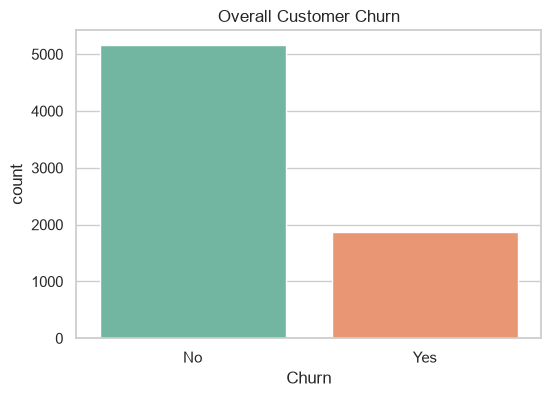

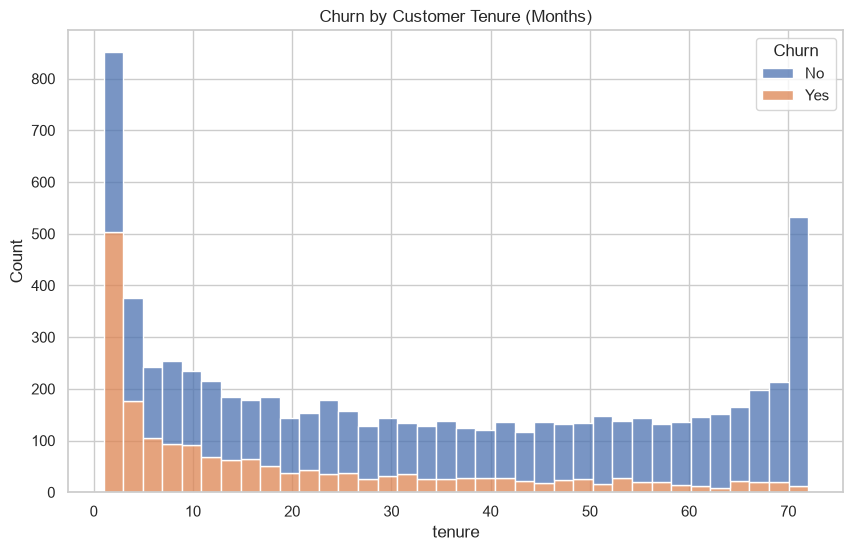

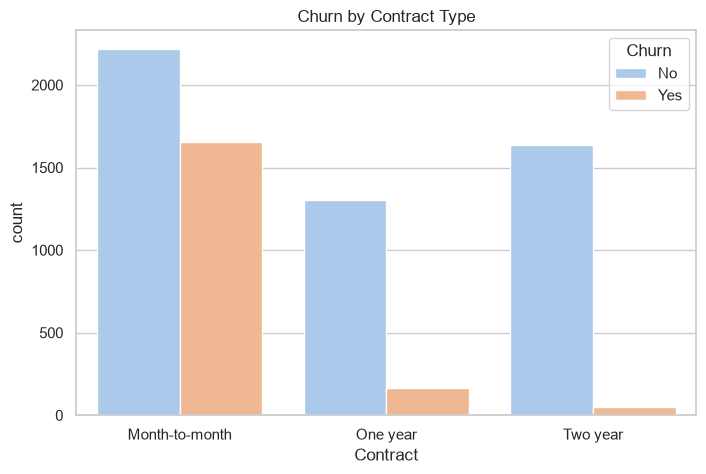

In [39]:
# 1. Look at the overall Churn distribution (The Target Variable)
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=df, palette='Set2')
plt.title('Overall Customer Churn')
plt.show()

# 2. Does customer loyalty (tenure) affect churn?
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', bins=36)
plt.title('Churn by Customer Tenure (Months)')
plt.show()

# 3. Do contract types matter?
plt.figure(figsize=(8, 5))
sns.countplot(x='Contract', hue='Churn', data=df, palette='pastel')
plt.title('Churn by Contract Type')
plt.show()

In [40]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# 1. Load and prep the raw data
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Fix the known blank space issue in TotalCharges and drop the resulting NaNs
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.dropna(subset=['TotalCharges'], inplace=True)

# Separate features (X) and target (y). Drop useless identifiers.
X = df.drop(columns=['Churn', 'customerID', 'index'], errors='ignore')
y = df['Churn'].map({'Yes': 1, 'No': 0}) # Encode target to 1/0

# 2. Split into training and testing sets (stratified to maintain churn ratio)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Define feature groups
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
# Automatically grab all remaining text columns as categorical
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

# 4. Create preprocessing transformers
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()) # Optional for Random Forest, but good standard practice
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

# Combine transformers into a single preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# 5. Build the final Random Forest Pipeline
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    # class_weight='balanced' helps because churn data is usually imbalanced
    ('classifier', RandomForestClassifier(n_estimators=100,
                                          random_state=42,
                                          n_jobs=-1,
                                          class_weight='balanced'))
])

# 6. Train the model
rf_pipeline.fit(X_train, y_train)

# 7. Predict and Evaluate
y_pred = rf_pipeline.predict(X_test)
print(classification_report(y_test, y_pred))

C:\Users\Victus\AppData\Local\Temp\ipykernel_23592\1601821762.py:29: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=['object']).columns.tolist()


              precision    recall  f1-score   support

           0       0.86      0.80      0.83      1033
           1       0.54      0.64      0.59       374

    accuracy                           0.76      1407
   macro avg       0.70      0.72      0.71      1407
weighted avg       0.78      0.76      0.77      1407



C:\Users\Victus\AppData\Local\Temp\ipykernel_23592\4201075972.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=top_importances, palette='mako')


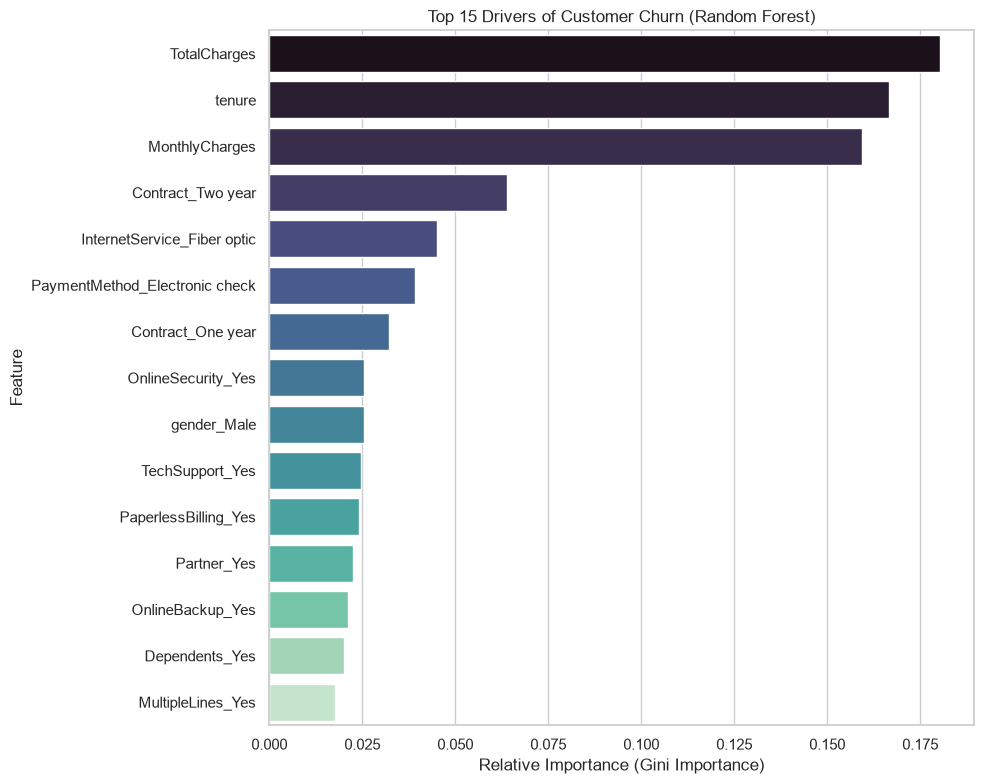

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract the trained model and preprocessor from the pipeline
classifier = rf_pipeline.named_steps['classifier']
preprocessor = rf_pipeline.named_steps['preprocessor']

# 2. Extract feature names
# Numeric features stay the same
num_cols = numeric_features
# Categorical features got expanded by OneHotEncoder, so we pull the new names
cat_cols = preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(categorical_features)

# Combine them into a single list
all_features = list(num_cols) + list(cat_cols)

# 3. Pair the feature names with their importance scores
importances = pd.DataFrame({
    'Feature': all_features,    'Importance': classifier.feature_importances_
})

# Sort to find the top 15 strongest predictors
top_importances = importances.sort_values(by='Importance', ascending=False).head(15)

# 4. Plot the results
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=top_importances, palette='mako')
plt.title('Top 15 Drivers of Customer Churn (Random Forest)')
plt.xlabel('Relative Importance (Gini Importance)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

C:\Users\Victus\AppData\Local\Temp\ipykernel_23592\2165360260.py:10: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(


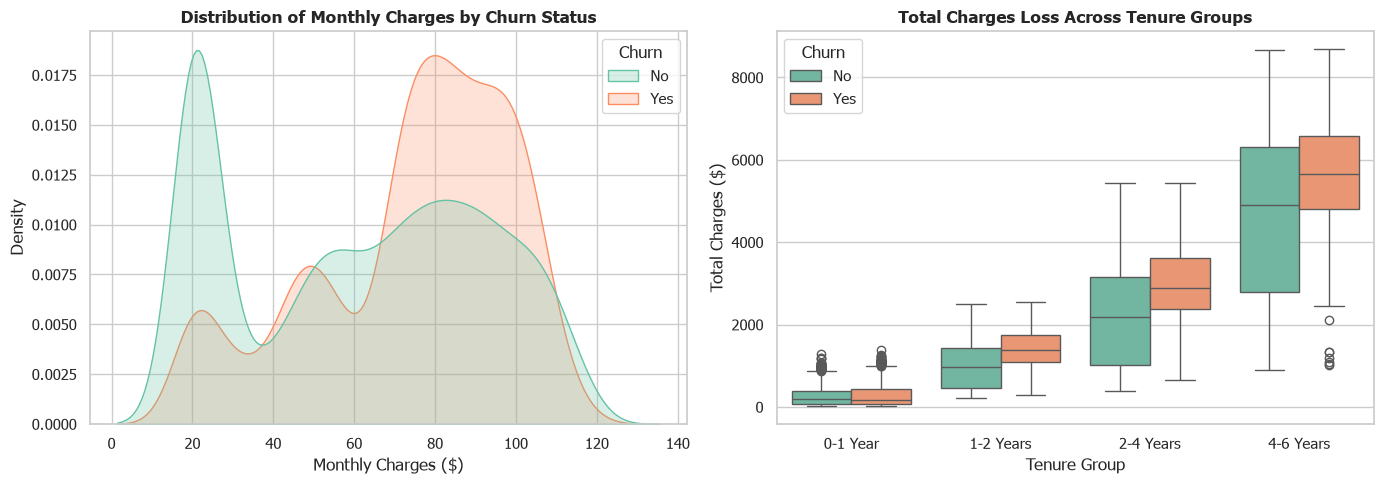

In [42]:
# ตั้งค่า Style กราฟให้ดูสะอาดและอ่านง่าย
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = ["Tahoma", "DejaVu Sans"]  # รองรับฟอนต์


# 1. พฤติกรรมการจ่ายเงินและรายได้ (Financial & Billing Insights)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1.1 Distribution ของ MonthlyCharges แยกตาม Churn
sns.kdeplot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    common_norm=False,
    shade=True,
    palette="Set2",
    ax=axes[0],
)
axes[0].set_title(
    "Distribution of Monthly Charges by Churn Status",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("Monthly Charges ($)")

# 1.2 Boxplot ของ TotalCharges ตาม Tenure Group
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-1 Year", "1-2 Years", "2-4 Years", "4-6 Years"],
)
sns.boxplot(
    data=df,
    x="TenureGroup",
    y="TotalCharges",
    hue="Churn",
    palette="Set2",
    ax=axes[1],
)
axes[1].set_title(
    "Total Charges Loss Across Tenure Groups", fontsize=12, fontweight="bold"
)
axes[1].set_xlabel("Tenure Group")
axes[1].set_ylabel("Total Charges ($)")

plt.tight_layout()
plt.show()


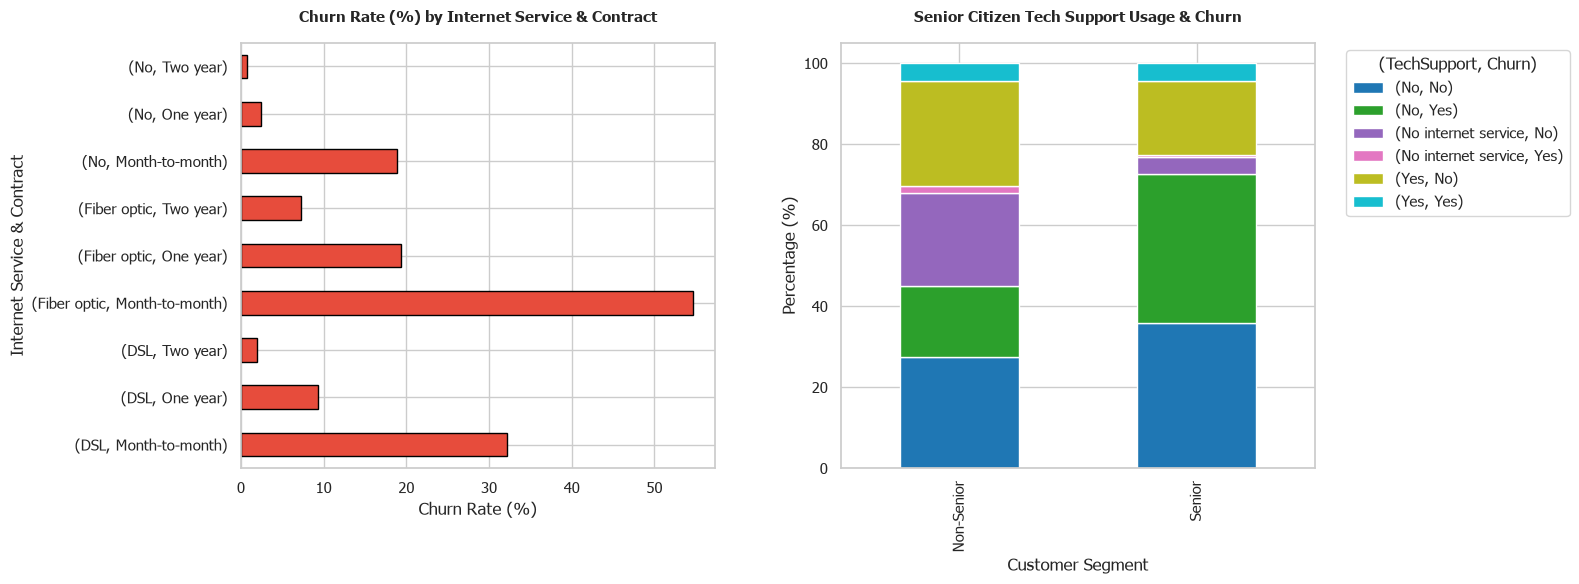

In [43]:
# 2. การเจาะลึกกลุ่มลูกค้าเสี่ยงสูง (Deep-dive High Risk Segments)
fig, axes = plt.subplots(1, 2, figsize=(16, 6)) # ขยายความกว้างนิดหน่อยเพื่อให้เลเบลฝั่งซ้ายไม่อึดอัด

# 2.1 Interaction: InternetService + Contract
high_risk_cross = (
    pd.crosstab(
        index=[df["InternetService"], df["Contract"]],
        columns=df["Churn"],
        normalize="index",
    )
    * 100
)
high_risk_cross["Yes"].plot(
    kind="barh", ax=axes[0], color="#e74c3c", edgecolor="black"
)
axes[0].set_title(
    "Churn Rate (%) by Internet Service & Contract",
    fontsize=11,
    fontweight="bold",
    pad=15,  # เพิ่มระยะห่างระหว่างชื่อกับกราฟ
)
axes[0].set_xlabel("Churn Rate (%)")
axes[0].set_ylabel("Internet Service & Contract")

# 2.2 Senior Citizen vs Tech Support Utilization
senior_tech = (
    pd.crosstab(
        index=df["SeniorCitizen"].map({0: "Non-Senior", 1: "Senior"}),
        columns=[df["TechSupport"], df["Churn"]],
        normalize="index",
    )
    * 100
)
senior_tech.plot(kind="bar", stacked=True, ax=axes[1], colormap="tab10")
axes[1].set_title(
    "Senior Citizen Tech Support Usage & Churn",
    fontsize=11,
    fontweight="bold",
    pad=15,  # เพิ่มระยะห่างระหว่างชื่อกับกราฟ
)
axes[1].set_ylabel("Percentage (%)")
axes[1].set_xlabel("Customer Segment")
axes[1].legend(title="(TechSupport, Churn)", bbox_to_anchor=(1.05, 1))

# ปรับระยะห่างระหว่างสองกราฟ (w_pad) ไม่ให้หัวข้อหรือเลเบลชนกัน
plt.tight_layout(w_pad=4.0)
plt.show()


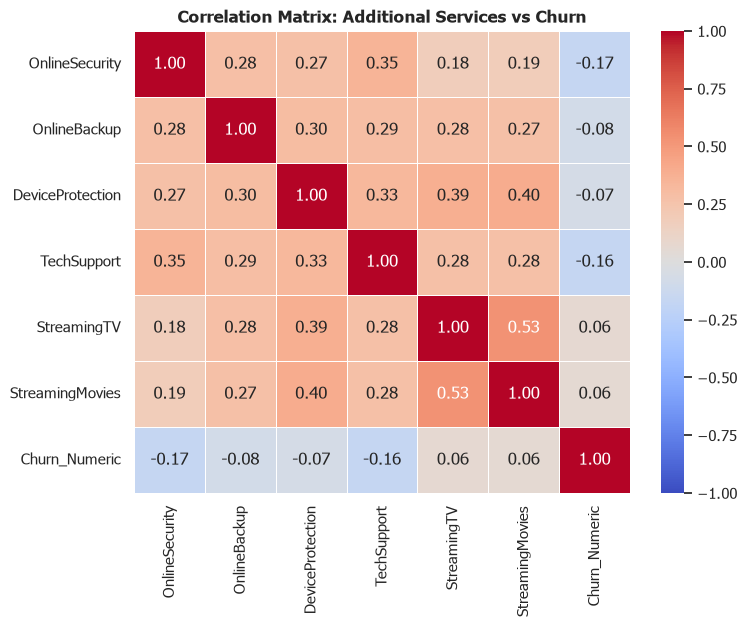

In [44]:
# 3. ความสัมพันธ์ระหว่างบริการเสริม (Service Bundle Correlation Matrix)
services = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
]

# แปลงค่าบริการเสริมเป็น Numeric (1 = มีบริการ, 0 = ไม่มี/ไม่มีอินเทอร์เน็ต)
service_df = df[services].copy()
for col in services:
    service_df[col] = service_df[col].apply(
        lambda x: 1 if x == "Yes" else 0
    )

service_df["Churn_Numeric"] = df["Churn"].apply(
    lambda x: 1 if x == "Yes" else 0
)

# คำนวณ Correlation Matrix
plt.figure(figsize=(8, 6))
corr = service_df.corr()
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmax=1,
    vmin=-1,
    linewidths=0.5,
)
plt.title(
    "Correlation Matrix: Additional Services vs Churn",
    fontsize=12,
    fontweight="bold",
)
plt.show()

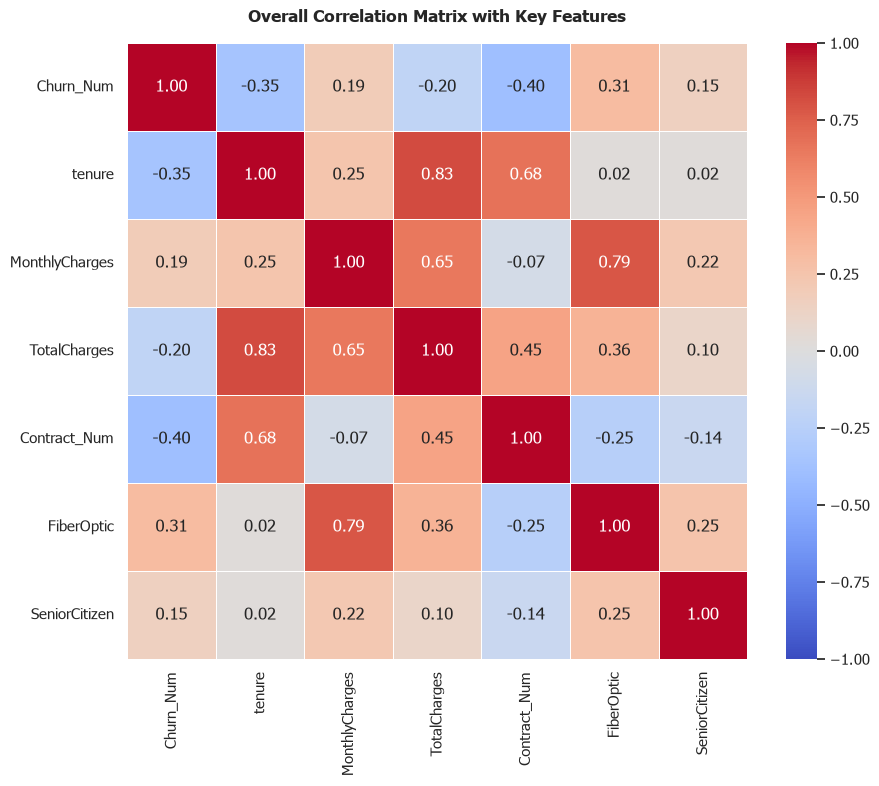

In [45]:
corr_df = df.copy()

# แปลง Target Variable
corr_df["Churn_Num"] = corr_df["Churn"].map({"Yes": 1, "No": 0})

# แปลง Contract (Ordinal Mapping)
contract_map = {"Month-to-month": 0, "One year": 1, "Two year": 2}
corr_df["Contract_Num"] = corr_df["Contract"].map(contract_map)

# แปลง InternetService
corr_df["FiberOptic"] = (corr_df["InternetService"] == "Fiber optic").astype(
    int
)

# เลือกเฉพาะ Feature ที่ต้องการดูความสัมพันธ์
selected_features = [
    "Churn_Num",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "Contract_Num",
    "FiberOptic",
    "SeniorCitizen",
]

# 2. คำนวณ Correlation และแสดง Heatmap
plt.figure(figsize=(10, 8))
correlation = corr_df[selected_features].corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmax=1,
    vmin=-1,
    linewidths=0.5,
)
plt.title(
    "Overall Correlation Matrix with Key Features",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
plt.show()

In [46]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import classification_report, mean_squared_error, r2_score

# 1. Define Features and Targets
# CRITICAL FIX: Drop 'TotalCharges' entirely, and drop 'tenure' from features
X = df.drop(columns=['Churn', 'TotalCharges', 'tenure', 'customerID'], errors='ignore')

# Target 1: Classification (Will they churn?)
y_clf = df['Churn'].map({'Yes': 1, 'No': 0})

# Target 2: Regression (How many months will they stay?)
y_reg = df['tenure']

# Split data
X_train, X_test, y_clf_train, y_clf_test, y_reg_train, y_reg_test = train_test_split(
    X, y_clf, y_reg, test_size=0.2, random_state=42, stratify=y_clf
)
# 3. Build Preprocessor
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_features),
        ('cat', Pipeline(steps=[('imputer', SimpleImputer(strategy='constant', fill_value='missing')), ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))]), categorical_features)
    ])

# 4. Define the Two Models
clf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1))
])

reg_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(random_state=42, n_jobs=-1))
])

# 5. Train Both Models
clf_model.fit(X_train, y_clf_train)
reg_model.fit(X_train, y_reg_train)

# 6. Predict and Evaluate
clf_preds = clf_model.predict(X_test)
reg_preds = reg_model.predict(X_test)

print("--- Churn Classification Results ---")
print(classification_report(y_clf_test, clf_preds))

print("\\n--- TotalCharges Regression Results ---")
# Fixed the RMSE calculation here:
rmse = np.sqrt(mean_squared_error(y_reg_test, reg_preds))
print(f"RMSE: {rmse:.2f}")
print(f"R2 Score: {r2_score(y_reg_test, reg_preds):.2f}")

C:\Users\Victus\AppData\Local\Temp\ipykernel_23592\1901841139.py:27: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=['object']).columns.tolist()


--- Churn Classification Results ---
              precision    recall  f1-score   support

           0       0.84      0.78      0.81      1033
           1       0.49      0.58      0.53       374

    accuracy                           0.73      1407
   macro avg       0.66      0.68      0.67      1407
weighted avg       0.74      0.73      0.73      1407

\n--- TotalCharges Regression Results ---
RMSE: 15.45
R2 Score: 0.60


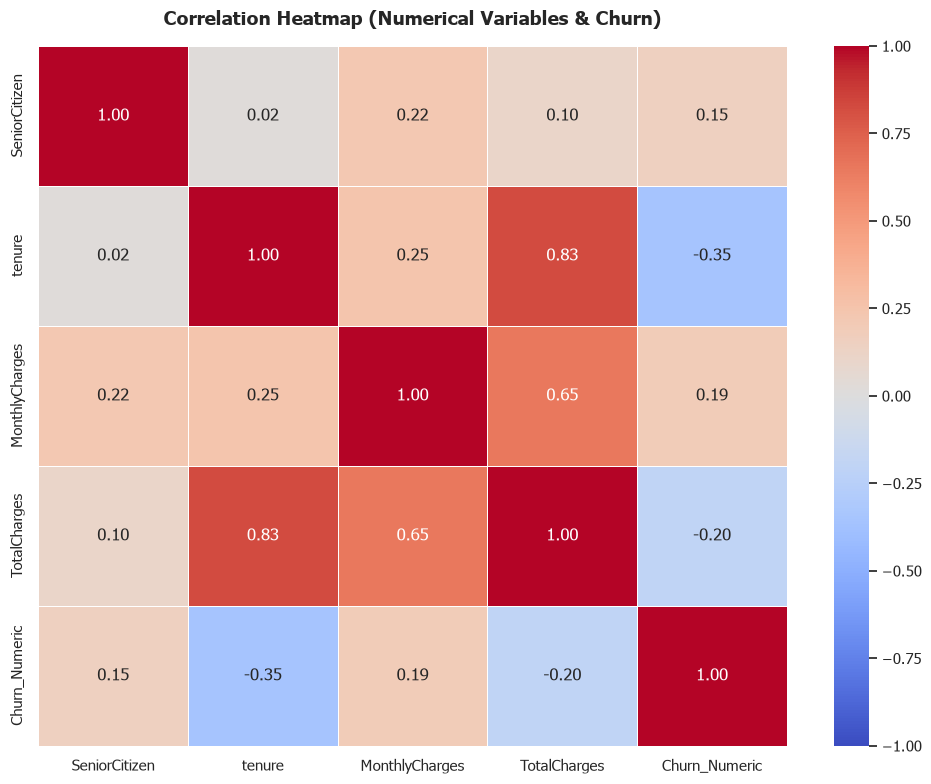

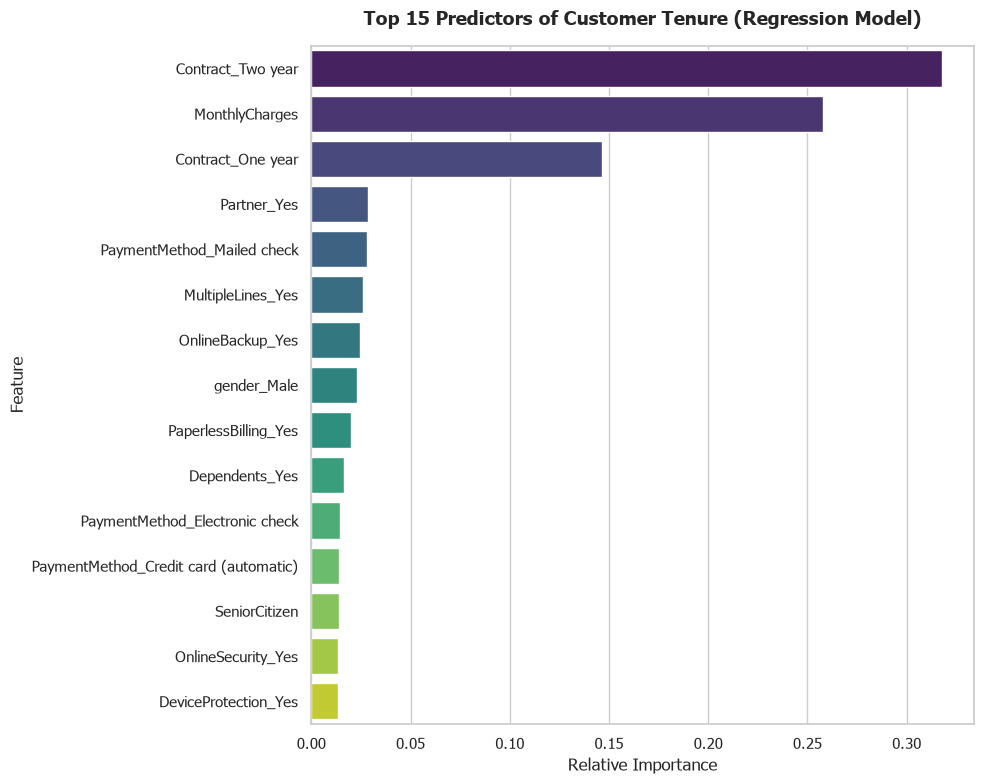

In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set up the visual style
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = ['Tahoma', 'DejaVu Sans']

# ==========================================
# 1. CORRELATION HEATMAP
# ==========================================
# Create a temporary numeric column for Churn to include it in the heatmap
df['Churn_Numeric'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Select only numeric columns
numeric_df = df.select_dtypes(include=['int64', 'float64'])

plt.figure(figsize=(10, 8))
# Plot the heatmap
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)
plt.title('Correlation Heatmap (Numerical Variables & Churn)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# ==========================================
# 2. REGRESSION FEATURE IMPORTANCE PLOT
# ==========================================
# Extract the trained regressor and preprocessor from your Pipeline
regressor = reg_model.named_steps['regressor']
preprocessor = reg_model.named_steps['preprocessor']

# Extract feature names (Numeric + One-Hot Encoded Categorical)
cat_cols = preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(categorical_features)
all_features = list(numeric_features) + list(cat_cols)

# Create a DataFrame of importances
reg_importances = pd.DataFrame({
    'Feature': all_features,
    'Importance': regressor.feature_importances_
})

# Get the top 15 most important features for predicting Tenure
top_reg_importances = reg_importances.sort_values(by='Importance', ascending=False).head(15)

plt.figure(figsize=(10, 8))
sns.barplot(
    data=top_reg_importances,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)
plt.title('Top 15 Predictors of Customer Tenure (Regression Model)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

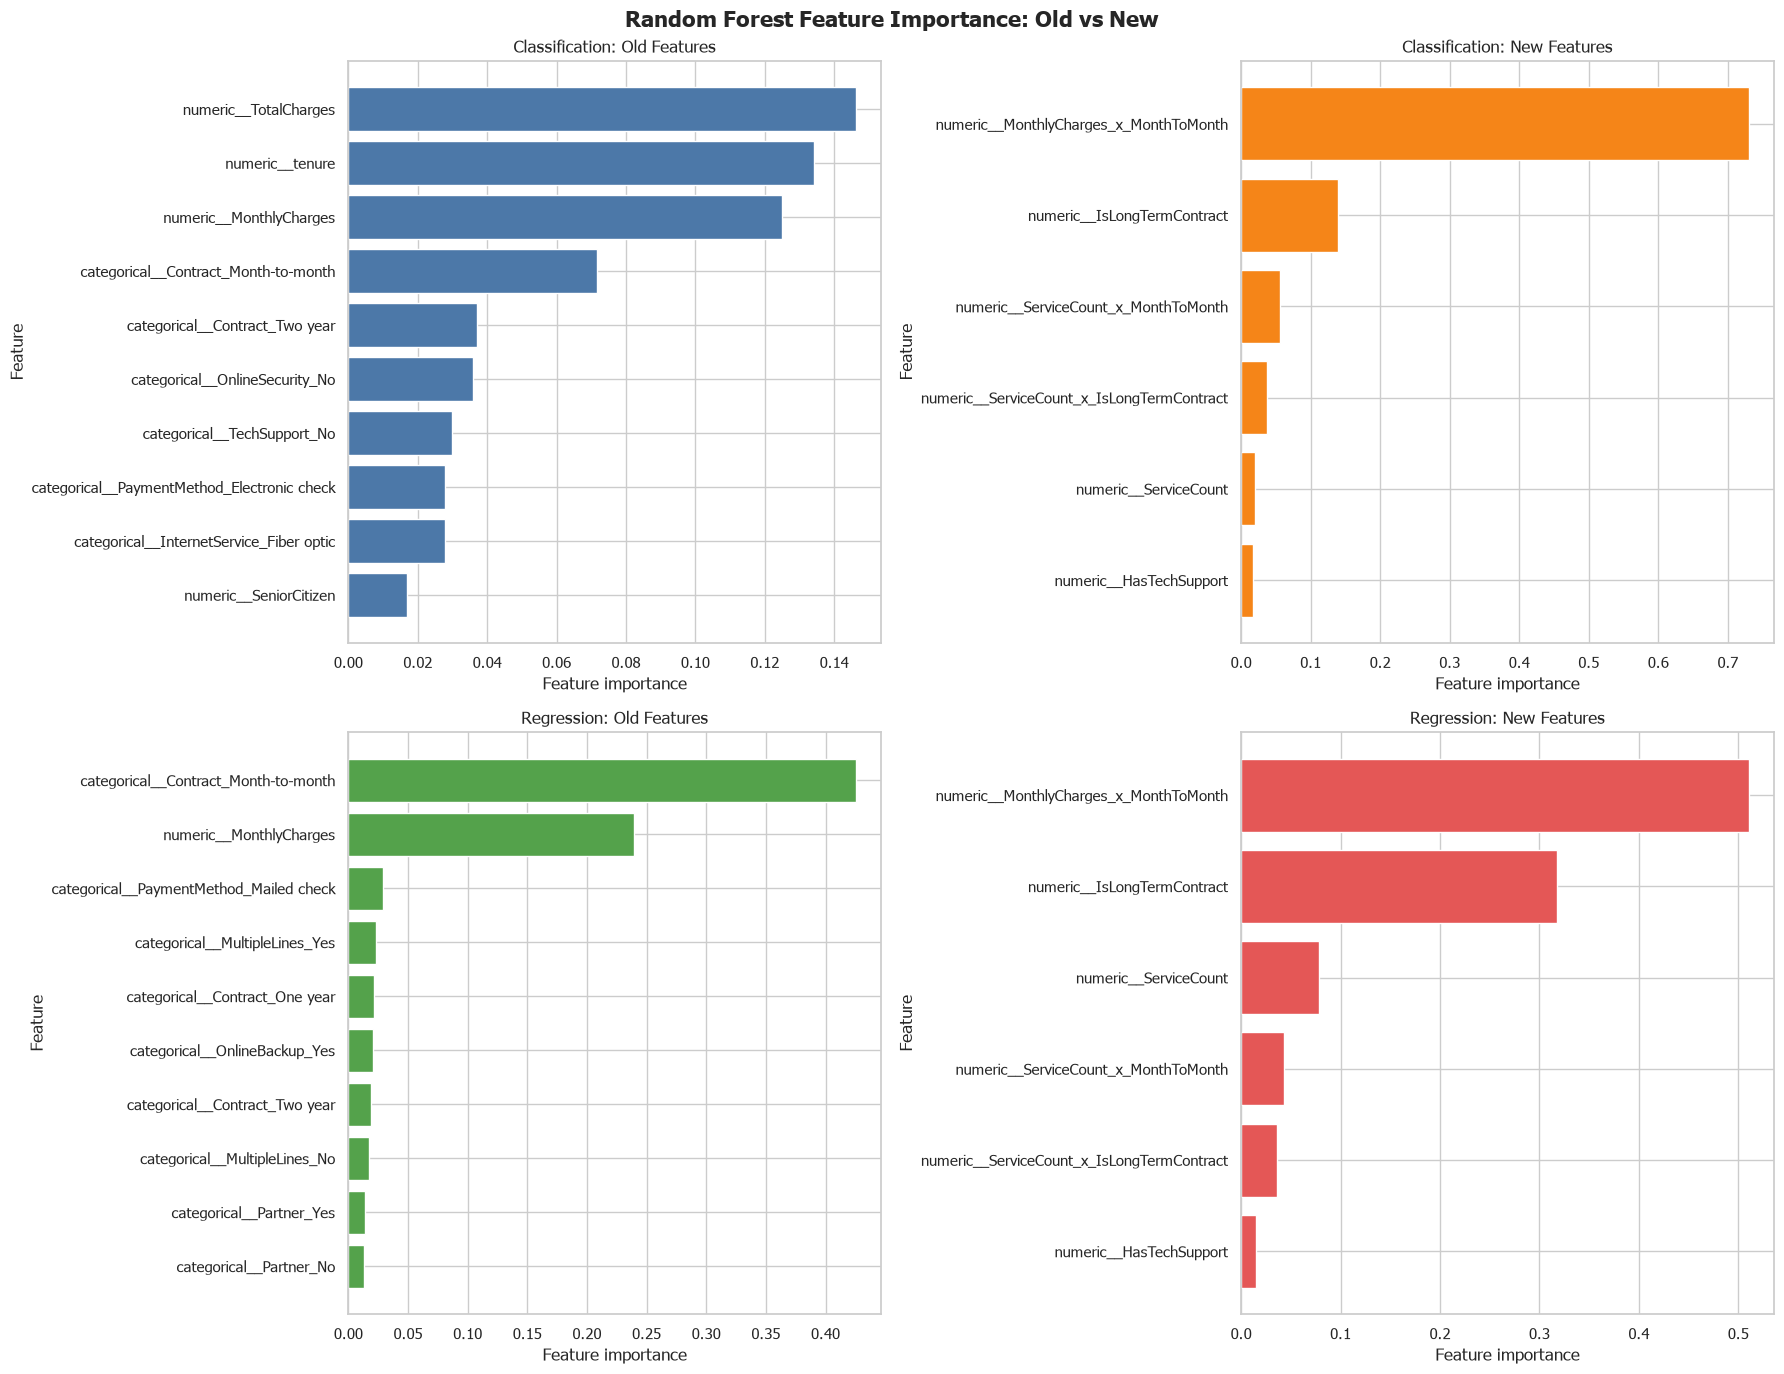

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Load data and create the combined and interaction features.
feature_df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
feature_df['TotalCharges'] = pd.to_numeric(feature_df['TotalCharges'], errors='coerce')
feature_df = feature_df.dropna(subset=['TotalCharges']).copy()

service_columns = [
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies'
]
new_feature_columns = [
    'ServiceCount',
    'IsLongTermContract',
    'HasTechSupport',
    'MonthlyCharges_x_MonthToMonth',
    'ServiceCount_x_MonthToMonth',
    'ServiceCount_x_IsLongTermContract'
]

feature_df['ServiceCount'] = feature_df[service_columns].eq('Yes').sum(axis=1)
feature_df['IsLongTermContract'] = feature_df['Contract'].isin(
    ['One year', 'Two year']
).astype(int)
feature_df['HasTechSupport'] = feature_df['TechSupport'].eq('Yes').astype(int)

# Interaction features combine customer spending, contract type, and service usage.
month_to_month = feature_df['Contract'].eq('Month-to-month').astype(int)
feature_df['MonthlyCharges_x_MonthToMonth'] = (
    feature_df['MonthlyCharges'] * month_to_month
)
feature_df['ServiceCount_x_MonthToMonth'] = (
    feature_df['ServiceCount'] * month_to_month
)
feature_df['ServiceCount_x_IsLongTermContract'] = (
    feature_df['ServiceCount'] * feature_df['IsLongTermContract']
)

# Keep the original and new feature sets separate for a fair graph comparison.
classification_old = feature_df.drop(
    columns=['Churn', 'customerID', 'index'] + new_feature_columns,
    errors='ignore'
)
classification_new = feature_df[new_feature_columns]
classification_target = feature_df['Churn'].map({'Yes': 1, 'No': 0})

regression_old = feature_df.drop(
    columns=['Churn', 'tenure', 'TotalCharges', 'customerID', 'index'] + new_feature_columns,
    errors='ignore'
)
regression_new = feature_df[new_feature_columns]
regression_target = feature_df['tenure']

def make_preprocessor(features):
    numeric_columns = features.select_dtypes(include=['number']).columns.tolist()
    categorical_columns = [
        column for column in features.columns
        if column not in numeric_columns
    ]
    return ColumnTransformer([
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_columns),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_columns)
    ])

def get_importance(features, target, task):
    if task == 'classification':
        estimator = RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            class_weight='balanced'
        )
    else:
        estimator = RandomForestRegressor(
            n_estimators=300,
            random_state=42
        )

    model = Pipeline([
        ('preprocessor', make_preprocessor(features)),
        ('model', estimator)
    ])
    model.fit(features, target)
    names = model.named_steps['preprocessor'].get_feature_names_out()
    importance = model.named_steps['model'].feature_importances_
    return pd.DataFrame({
        'Feature': names,
        'Importance': importance
    }).sort_values('Importance', ascending=False)

classification_old_importance = get_importance(
    classification_old, classification_target, 'classification'
)
classification_new_importance = get_importance(
    classification_new, classification_target, 'classification'
)
regression_old_importance = get_importance(
    regression_old, regression_target, 'regression'
)
regression_new_importance = get_importance(
    regression_new, regression_target, 'regression'
)

# The only output of this cell: four Random Forest feature-importance graphs.
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

plots = [
    (axes[0, 0], classification_old_importance.head(10), 'Classification: Old Features', '#4C78A8'),
    (axes[0, 1], classification_new_importance, 'Classification: New Features', '#F58518'),
    (axes[1, 0], regression_old_importance.head(10), 'Regression: Old Features', '#54A24B'),
    (axes[1, 1], regression_new_importance, 'Regression: New Features', '#E45756')
]

for axis, importance_data, title, color in plots:
    importance_data = importance_data.sort_values('Importance')
    axis.barh(importance_data['Feature'], importance_data['Importance'], color=color)
    axis.set_title(title)
    axis.set_xlabel('Feature importance')
    axis.set_ylabel('Feature')

fig.suptitle('Random Forest Feature Importance: Old vs New', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

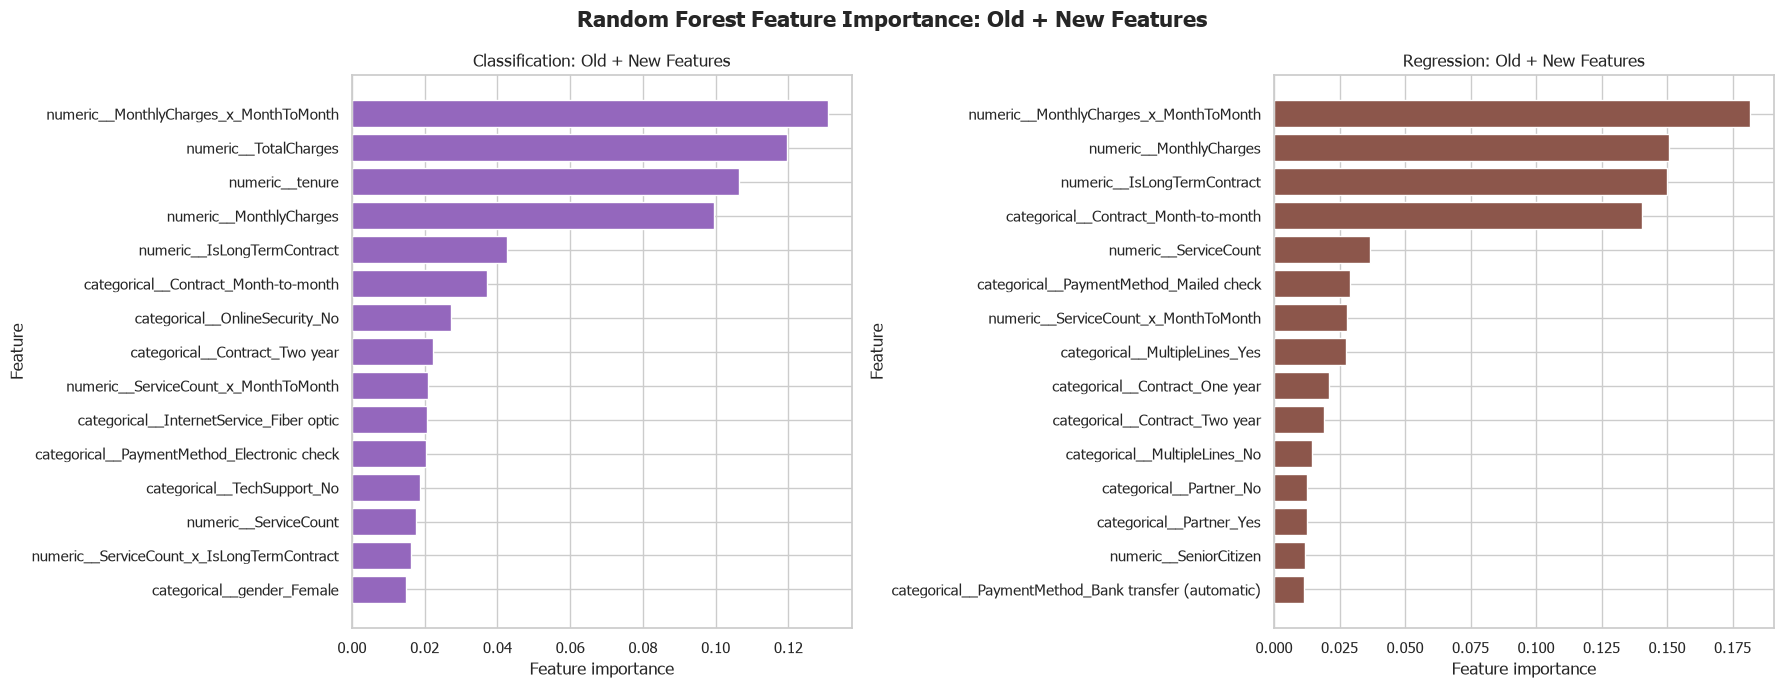

In [49]:
# Additional comparison: original features combined with the new engineered features.
classification_combined = feature_df.drop(
    columns=['Churn', 'customerID', 'index'],
    errors='ignore'
)
regression_combined = feature_df.drop(
    columns=['Churn', 'tenure', 'TotalCharges', 'customerID', 'index'],
    errors='ignore'
)

classification_combined_importance = get_importance(
    classification_combined,
    classification_target,
    'classification'
)
regression_combined_importance = get_importance(
    regression_combined,
    regression_target,
    'regression'
)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

classification_combined_plot = classification_combined_importance.head(15).sort_values('Importance')
axes[0].barh(
    classification_combined_plot['Feature'],
    classification_combined_plot['Importance'],
    color='#9467BD'
)
axes[0].set_title('Classification: Old + New Features')
axes[0].set_xlabel('Feature importance')
axes[0].set_ylabel('Feature')

regression_combined_plot = regression_combined_importance.head(15).sort_values('Importance')
axes[1].barh(
    regression_combined_plot['Feature'],
    regression_combined_plot['Importance'],
    color='#8C564B'
)
axes[1].set_title('Regression: Old + New Features')
axes[1].set_xlabel('Feature importance')
axes[1].set_ylabel('Feature')

fig.suptitle('Random Forest Feature Importance: Old + New Features', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## Compare Before vs After: Classification Evaluation

- **Before:** Random Forest using old features only
- **After:** Random Forest using old features plus the new combined and interaction features

Both models use the same train/test split. The evaluation includes Accuracy, Precision, Recall, F1, ROC-AUC, and Confusion Matrix.

Evaluation results:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Before: Old Features,0.7605,0.5414,0.6471,0.5895,0.8154
1,After: Old + New Features,0.7598,0.5404,0.6444,0.5878,0.8149


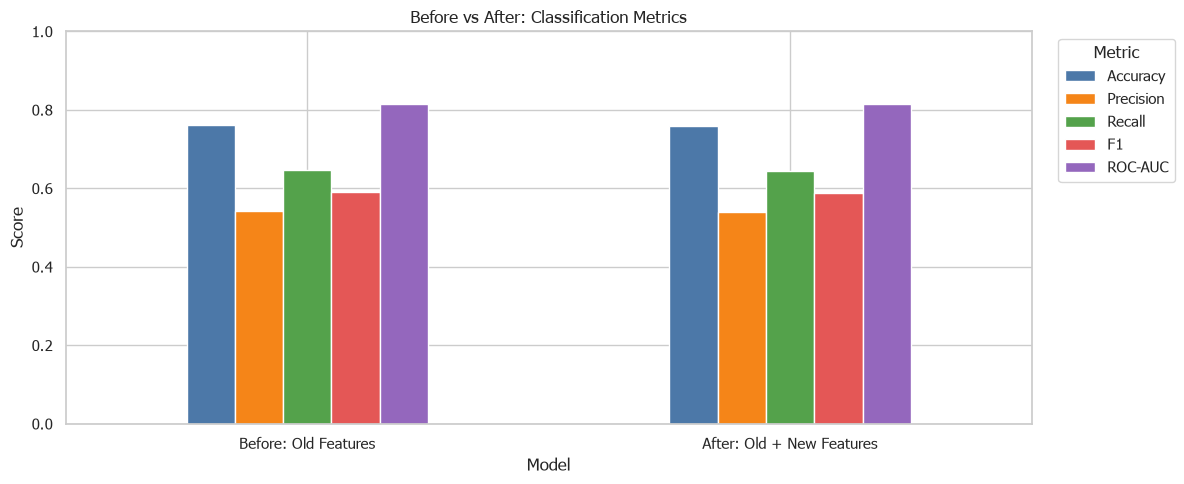

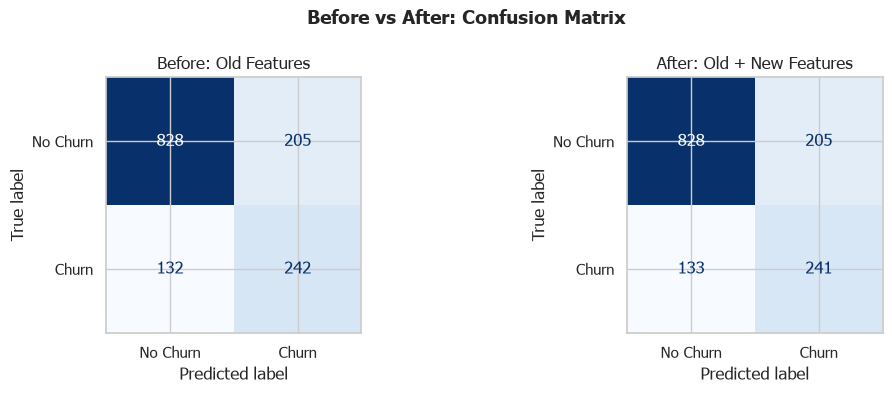

In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split

# Use exactly the same split for both models.
evaluation_indices = np.arange(len(feature_df))
train_indices, test_indices = train_test_split(
    evaluation_indices,
    test_size=0.2,
    random_state=42,
    stratify=classification_target
)

def make_classification_model(features):
    return Pipeline([
        ('preprocessor', make_preprocessor(features)),
        ('model', RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            class_weight='balanced'
        ))
    ])

def evaluate_classification_model(name, features):
    model = make_classification_model(features)
    model.fit(
        features.iloc[train_indices],
        classification_target.iloc[train_indices]
    )
    predictions = model.predict(features.iloc[test_indices])
    probabilities = model.predict_proba(features.iloc[test_indices])[:, 1]
    actual = classification_target.iloc[test_indices]

    return {
        'Model': name,
        'Accuracy': accuracy_score(actual, predictions),
        'Precision': precision_score(actual, predictions, zero_division=0),
        'Recall': recall_score(actual, predictions, zero_division=0),
        'F1': f1_score(actual, predictions, zero_division=0),
        'ROC-AUC': roc_auc_score(actual, probabilities),
        'Predictions': predictions,
        'Actual': actual
    }

before_result = evaluate_classification_model(
    'Before: Old Features',
    classification_old
)
after_result = evaluate_classification_model(
    'After: Old + New Features',
    classification_combined
)

results_for_display = pd.DataFrame([
    {metric: before_result[metric] for metric in ['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']},
    {metric: after_result[metric] for metric in ['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']}
])

print('Evaluation results:')
display(results_for_display.round(4))

# Compare the five evaluation metrics.
metric_columns = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
results_for_display.set_index('Model')[metric_columns].plot(
    kind='bar',
    figsize=(12, 5),
    color=['#4C78A8', '#F58518', '#54A24B', '#E45756', '#9467BD']
)
plt.title('Before vs After: Classification Metrics')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Metric', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Compare confusion matrices using the same test observations.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for axis, result in zip(axes, [before_result, after_result]):
    ConfusionMatrixDisplay(
        confusion_matrix(result['Actual'], result['Predictions']),
        display_labels=['No Churn', 'Churn']
    ).plot(ax=axis, cmap='Blues', colorbar=False)
    axis.set_title(result['Model'])

fig.suptitle('Before vs After: Confusion Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Compare Individual Interaction Features

This section evaluates each requested interaction separately against the same old-feature baseline and the same train/test split.

Comparison 1: MonthlyCharges x MonthToMonth


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Old,0.7605,0.5414,0.6471,0.5895,0.8154
1,Old + MonthlyCharges x MonthToMonth,0.7711,0.5591,0.6578,0.6044,0.8138


Comparison 2: ServiceCount interactions


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Old,0.7605,0.5414,0.6471,0.5895,0.8154
1,Old + ServiceCount x MonthToMonth,0.7612,0.5434,0.6364,0.5862,0.8119
2,Old + ServiceCount x IsLongTermContract,0.7647,0.5479,0.6578,0.5978,0.8163


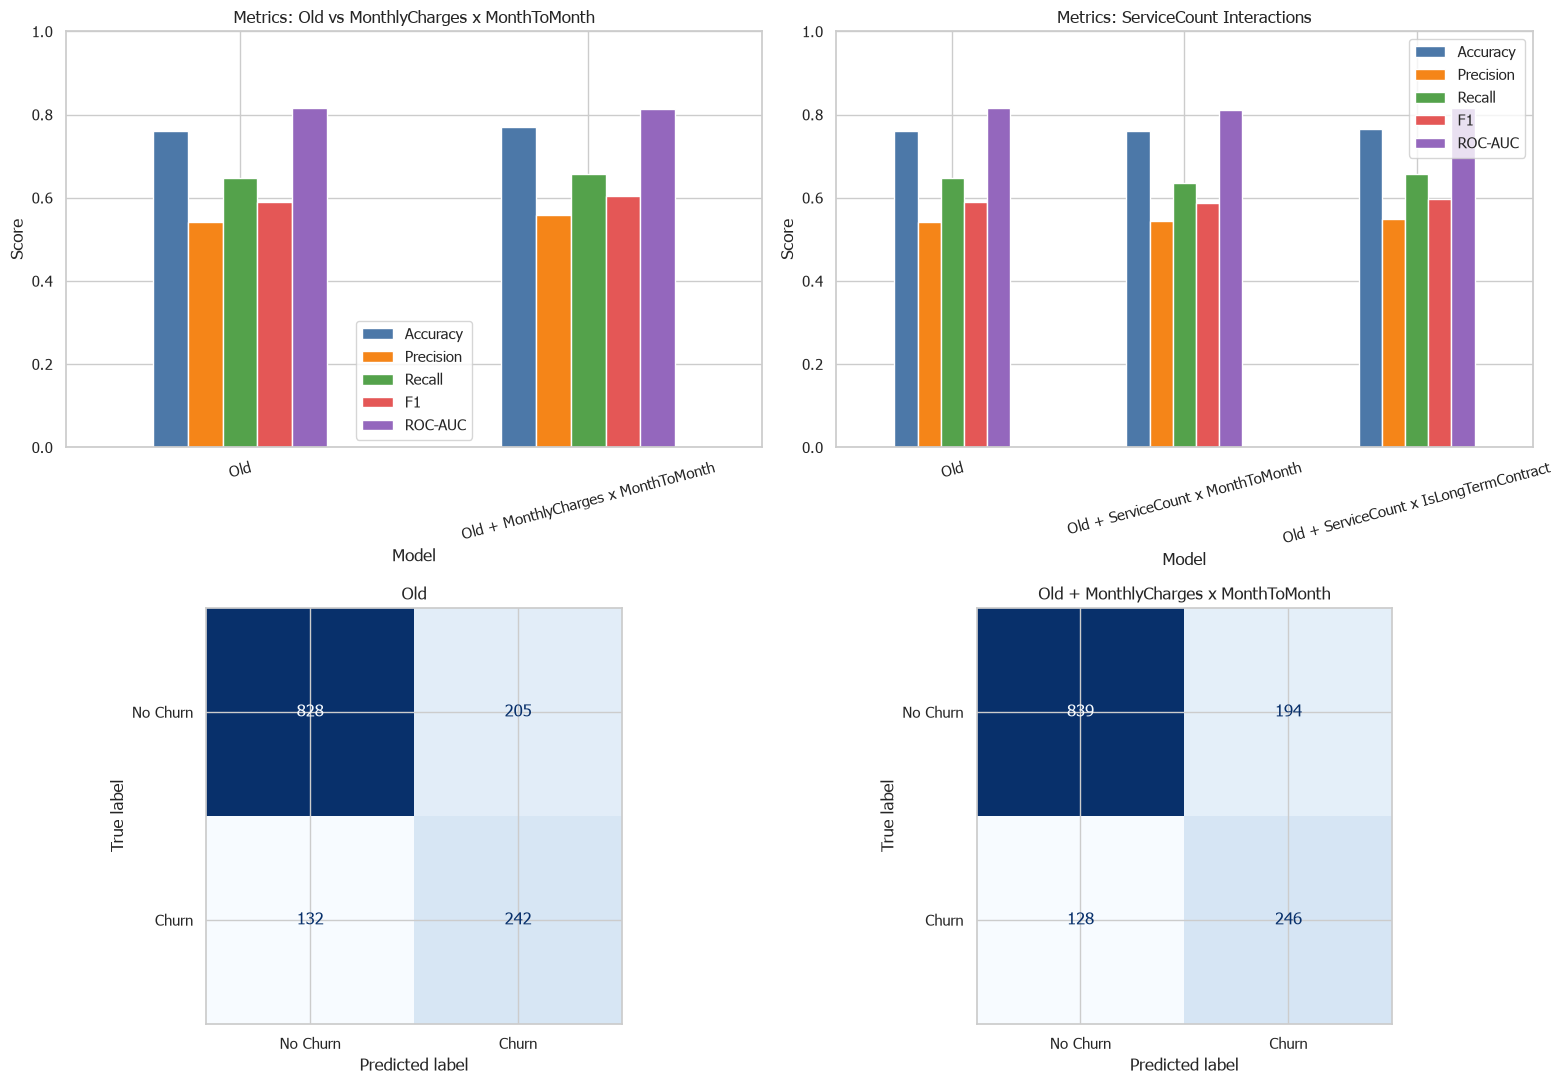

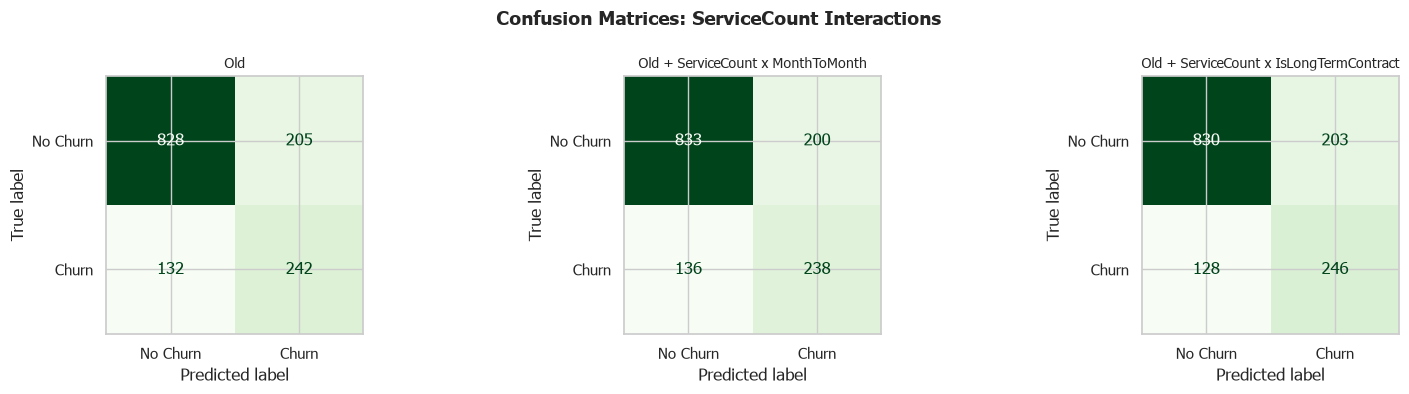

In [51]:
# Build each requested interaction on top of the old features only.
month_to_month = feature_df['Contract'].eq('Month-to-month').astype(int)
service_count = feature_df[service_columns].eq('Yes').sum(axis=1)
is_long_term = feature_df['Contract'].isin(['One year', 'Two year']).astype(int)

old_plus_monthly = classification_old.copy()
old_plus_monthly['MonthlyCharges_x_MonthToMonth'] = (
    feature_df['MonthlyCharges'] * month_to_month
)

old_plus_service_month = classification_old.copy()
old_plus_service_month['ServiceCount_x_MonthToMonth'] = (
    service_count * month_to_month
)

old_plus_service_long_term = classification_old.copy()
old_plus_service_long_term['ServiceCount_x_IsLongTermContract'] = (
    service_count * is_long_term
)

def build_comparison_table(model_inputs):
    evaluated_results = [
        evaluate_classification_model(name, features)
        for name, features in model_inputs
    ]
    return pd.DataFrame([
        {
            metric: result[metric]
            for metric in ['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
        }
        for result in evaluated_results
    ]), evaluated_results

monthly_results, monthly_details = build_comparison_table([
    ('Old', classification_old),
    ('Old + MonthlyCharges x MonthToMonth', old_plus_monthly)
])

service_results, service_details = build_comparison_table([
    ('Old', classification_old),
    ('Old + ServiceCount x MonthToMonth', old_plus_service_month),
    ('Old + ServiceCount x IsLongTermContract', old_plus_service_long_term)
])

print('Comparison 1: MonthlyCharges x MonthToMonth')
display(monthly_results.round(4))
print('Comparison 2: ServiceCount interactions')
display(service_results.round(4))

metric_columns = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

monthly_results.set_index('Model')[metric_columns].plot(
    kind='bar', ax=axes[0, 0],
    color=['#4C78A8', '#F58518', '#54A24B', '#E45756', '#9467BD']
)
axes[0, 0].set_title('Metrics: Old vs MonthlyCharges x MonthToMonth')
axes[0, 0].set_ylabel('Score')
axes[0, 0].set_ylim(0, 1)
axes[0, 0].tick_params(axis='x', rotation=15)

service_results.set_index('Model')[metric_columns].plot(
    kind='bar', ax=axes[0, 1],
    color=['#4C78A8', '#F58518', '#54A24B', '#E45756', '#9467BD']
)
axes[0, 1].set_title('Metrics: ServiceCount Interactions')
axes[0, 1].set_ylabel('Score')
axes[0, 1].set_ylim(0, 1)
axes[0, 1].tick_params(axis='x', rotation=15)

for axis, result in zip(axes[1, :], monthly_details):
    ConfusionMatrixDisplay(
        confusion_matrix(result['Actual'], result['Predictions']),
        display_labels=['No Churn', 'Churn']
    ).plot(ax=axis, cmap='Blues', colorbar=False)
    axis.set_title(result['Model'])

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for axis, result in zip(axes, service_details):
    ConfusionMatrixDisplay(
        confusion_matrix(result['Actual'], result['Predictions']),
        display_labels=['No Churn', 'Churn']
    ).plot(ax=axis, cmap='Greens', colorbar=False)
    axis.set_title(result['Model'], fontsize=10)

fig.suptitle('Confusion Matrices: ServiceCount Interactions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 5-Fold Cross-Validation: Individual Feature Effects

This cell evaluates each engineered feature separately against the same old-feature baseline.

5-fold cross-validation for each feature separately:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Old,0.7749,0.5672,0.6469,0.6044,0.8233
1,Old + ServiceCount,0.7749,0.5676,0.6447,0.6036,0.8235
2,Old + HasTechSupport,0.7736,0.5651,0.6474,0.6033,0.8226
3,Old + IsLongTermContract,0.7728,0.5634,0.6474,0.6024,0.8237
4,Old + MonthlyCharges x MonthToMonth,0.7747,0.5671,0.6474,0.6045,0.8251
5,Old + ServiceCount x MonthToMonth,0.7747,0.5669,0.6490,0.6051,0.8237
6,Old + ServiceCount x IsLongTermContract,0.7736,0.5649,0.6480,0.6034,0.8240


5-fold cross-validation for each feature separately:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Old,0.7749,0.5672,0.6469,0.6044,0.8233
1,Old + ServiceCount,0.7749,0.5676,0.6447,0.6036,0.8235
2,Old + HasTechSupport,0.7736,0.5651,0.6474,0.6033,0.8226
3,Old + IsLongTermContract,0.7728,0.5634,0.6474,0.6024,0.8237
4,Old + MonthlyCharges x MonthToMonth,0.7747,0.5671,0.6474,0.6045,0.8251
5,Old + ServiceCount x MonthToMonth,0.7747,0.5669,0.6490,0.6051,0.8237
6,Old + ServiceCount x IsLongTermContract,0.7736,0.5649,0.6480,0.6034,0.8240


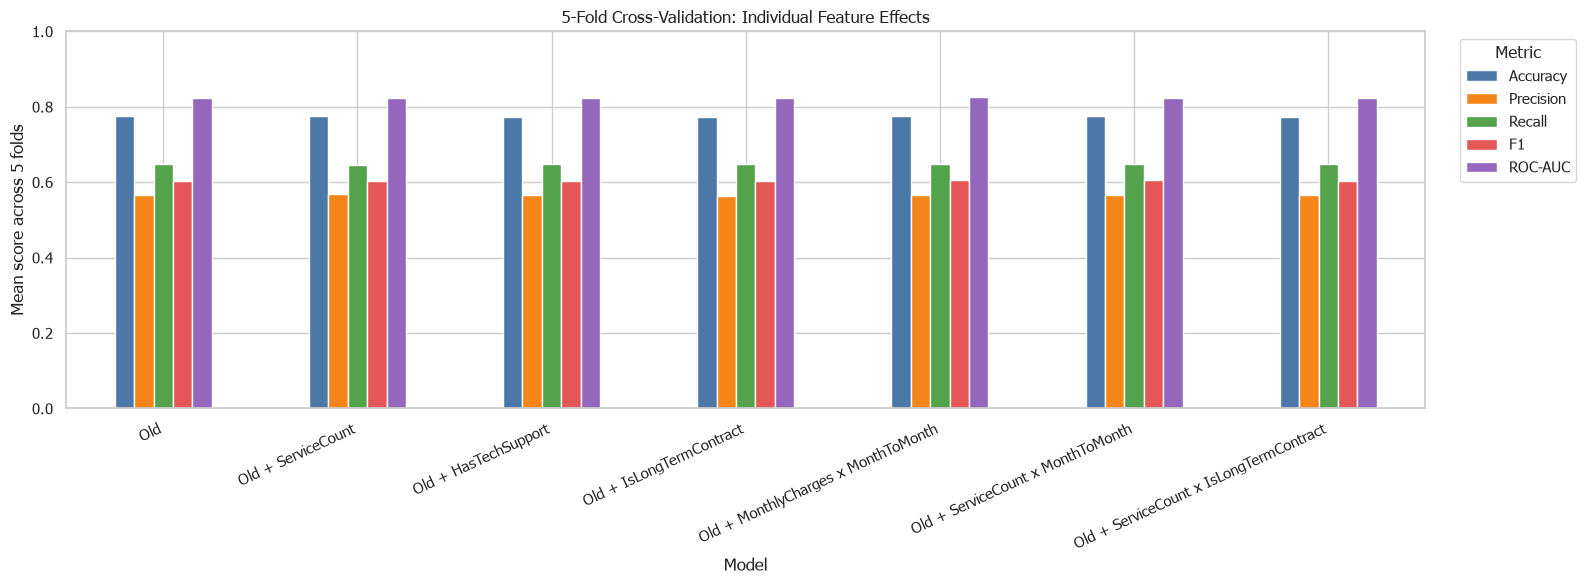

In [53]:
# Evaluate every engineered feature separately against Old.
individual_feature_sets = {
    'Old': classification_old,
    'Old + ServiceCount': classification_old.assign(
        ServiceCount=service_count
    ),
    'Old + HasTechSupport': classification_old.assign(
        HasTechSupport=feature_df['TechSupport'].eq('Yes').astype(int)
    ),
    'Old + IsLongTermContract': classification_old.assign(
        IsLongTermContract=is_long_term
    ),
    'Old + MonthlyCharges x MonthToMonth': old_plus_monthly,
    'Old + ServiceCount x MonthToMonth': old_plus_service_month,
    'Old + ServiceCount x IsLongTermContract': old_plus_service_long_term
}

individual_cv_results = []
for model_name, features in individual_feature_sets.items():
    cv_model = make_classification_model(features)
    scores = cross_validate(
        cv_model,
        features,
        classification_target,
        cv=cv_splitter,
        scoring=cv_scoring,
        n_jobs=-1
    )
    individual_cv_results.append({
        'Model': model_name,
        'Accuracy': scores['test_Accuracy'].mean(),
        'Precision': scores['test_Precision'].mean(),
        'Recall': scores['test_Recall'].mean(),
        'F1': scores['test_F1'].mean(),
        'ROC-AUC': scores['test_ROC-AUC'].mean()
    })

individual_cv_results = pd.DataFrame(individual_cv_results)
print('5-fold cross-validation for each feature separately:')
display(individual_cv_results.round(4))

individual_cv_results.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
].plot(
    kind='bar',
    figsize=(16, 6),
    color=['#4C78A8', '#F58518', '#54A24B', '#E45756', '#9467BD']
)
plt.title('5-Fold Cross-Validation: Individual Feature Effects')
plt.ylabel('Mean score across 5 folds')
plt.ylim(0, 1)
plt.xticks(rotation=25, ha='right')
plt.legend(title='Metric', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 5-Fold Cross-Validation: Regression Feature Effects

This cell checks which engineered feature improves the Random Forest regression model for predicting customer tenure.

5-fold cross-validation for regression feature effects:


,Model,RMSE,MAE,R2
0,Old,15.6357,12.0078,0.5940
1,Old + ServiceCount,15.6215,11.9921,0.5947
2,Old + HasTechSupport,15.6404,12.0129,0.5937
3,Old + IsLongTermContract,15.6359,12.0109,0.5940
4,Old + MonthlyCharges x MonthToMonth,15.6280,11.9966,0.5944
5,Old + ServiceCount x MonthToMonth,15.6325,12.0023,0.5941
6,Old + ServiceCount x IsLongTermContract,15.6199,11.9942,0.5948


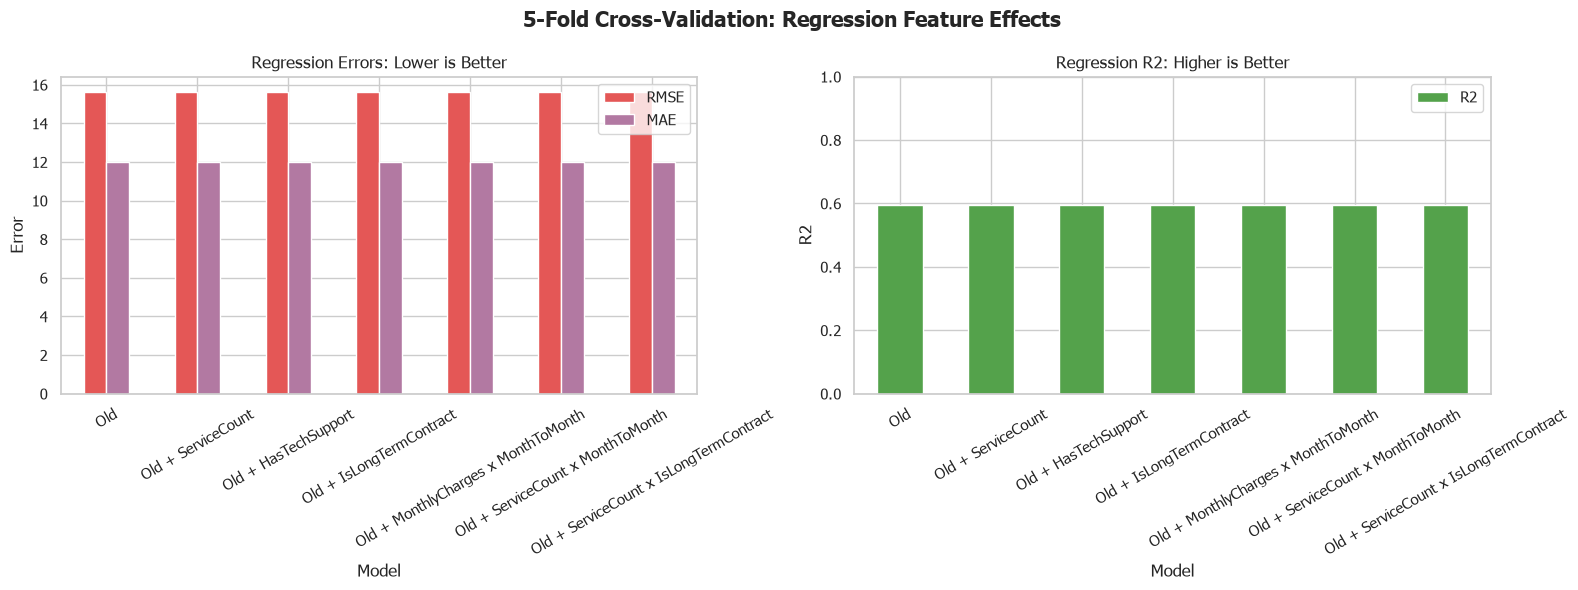

In [ ]:
from sklearn.metrics import make_scorer, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate

# Build regression feature sets one at a time.
regression_feature_sets = {
    'Old': regression_old,
    'Old + ServiceCount': regression_old.assign(
        ServiceCount=service_count
    ),
    'Old + HasTechSupport': regression_old.assign(
        HasTechSupport=feature_df['TechSupport'].eq('Yes').astype(int)
    ),
    'Old + IsLongTermContract': regression_old.assign(
        IsLongTermContract=is_long_term
    ),
    'Old + MonthlyCharges x MonthToMonth': regression_old.assign(
        MonthlyCharges_x_MonthToMonth=(
            feature_df['MonthlyCharges'] * month_to_month
        )
    ),
    'Old + ServiceCount x MonthToMonth': regression_old.assign(
        ServiceCount_x_MonthToMonth=(
            service_count * month_to_month
        )
    ),
    'Old + ServiceCount x IsLongTermContract': regression_old.assign(
        ServiceCount_x_IsLongTermContract=(
            service_count * is_long_term
        )
    )
}

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def make_regression_model(features):
    return Pipeline([
        ('preprocessor', make_preprocessor(features)),
        ('model', RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ))
    ])

regression_cv_scoring = {
    'RMSE': make_scorer(root_mean_squared_error, greater_is_better=False),
    'MAE': make_scorer(mean_absolute_error, greater_is_better=False),
    'R2': 'r2'
}

regression_cv_results = []
regression_cv_splitter = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for model_name, features in regression_feature_sets.items():
    regression_model_cv = make_regression_model(features)
    scores = cross_validate(
        regression_model_cv,
        features,
        regression_target,
        cv=regression_cv_splitter,
        scoring=regression_cv_scoring,
        n_jobs=-1
    )
    regression_cv_results.append({
        'Model': model_name,
        'RMSE': -scores['test_RMSE'].mean(),
        'MAE': -scores['test_MAE'].mean(),
        'R2': scores['test_R2'].mean()
    })

regression_cv_results = pd.DataFrame(regression_cv_results)
print('5-fold cross-validation for regression feature effects:')
display(regression_cv_results.round(4))

# Lower RMSE/MAE are better; higher R2 is better.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

regression_cv_results.set_index('Model')[['RMSE', 'MAE']].plot(
    kind='bar',
    ax=axes[0],
    color=['#E45756', '#B279A2']
)
axes[0].set_title('Regression Errors: Lower is Better')
axes[0].set_ylabel('Error')
axes[0].tick_params(axis='x', rotation=30)

regression_cv_results.set_index('Model')[['R2']].plot(
    kind='bar',
    ax=axes[1],
    color=['#54A24B']
)
axes[1].set_title('Regression R2: Higher is Better')
axes[1].set_ylabel('R2')
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis='x', rotation=30)

fig.suptitle('5-Fold Cross-Validation: Regression Feature Effects', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

## 5-Fold CV: Replacing Redundant Original Features

This experiment removes the original columns that are summarized by each engineered feature instead of keeping both versions. The main classification objective is Recall because missing a customer who will churn is costly.

5-fold CV with redundant source columns removed:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
3,Old + HasTechSupport (replace sources),0.7773,0.5718,0.6490,0.6078,0.8239
0,Old,0.7749,0.5672,0.6469,0.6044,0.8233
2,Old + IsLongTermContract (replace sources),0.7743,0.5671,0.6405,0.6014,0.8222
4,Old + MonthlyCharges_x_MonthToMonth (replace s...,0.7728,0.5645,0.6383,0.5990,0.8195
1,Old + ServiceCount (replace sources),0.7659,0.5520,0.6362,0.5910,0.8159
5,Old + ServiceCount_x_MonthToMonth (replace sou...,0.7648,0.5509,0.6244,0.5853,0.8126
6,Old + ServiceCount_x_IsLongTermContract (repla...,0.7618,0.5458,0.6212,0.5810,0.8112


<Figure size 1600x600 with 0 Axes>

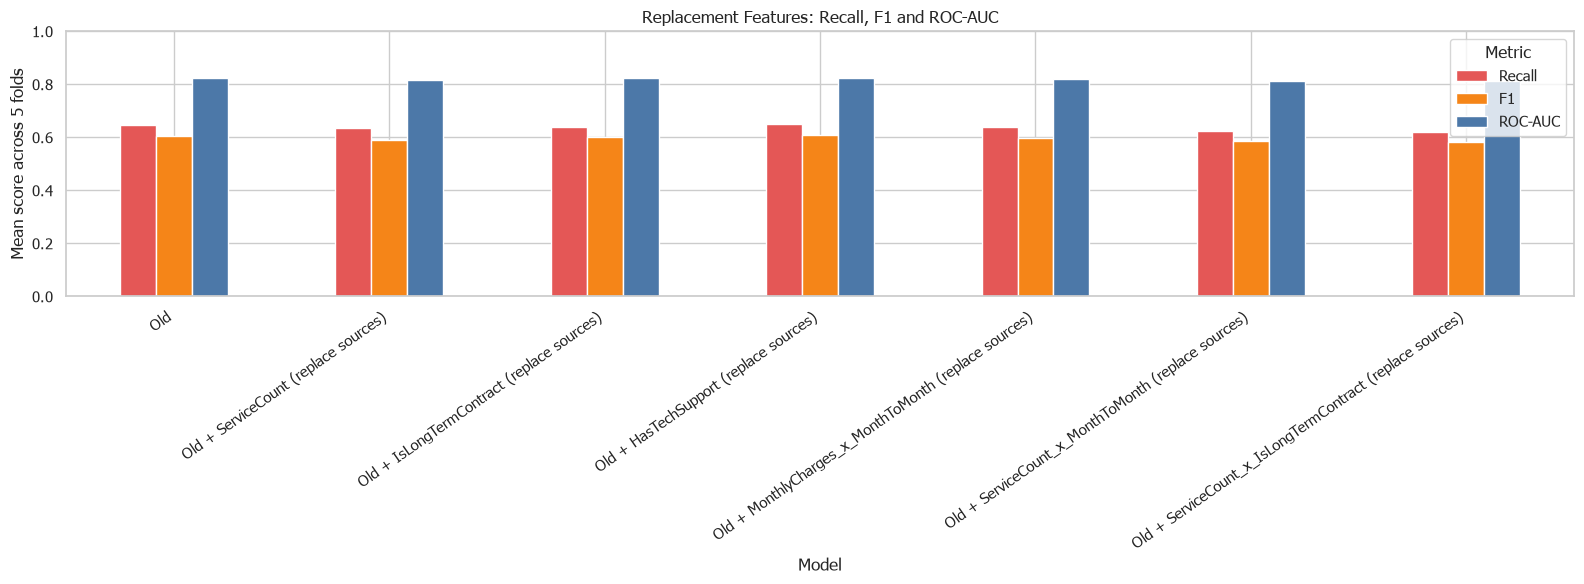

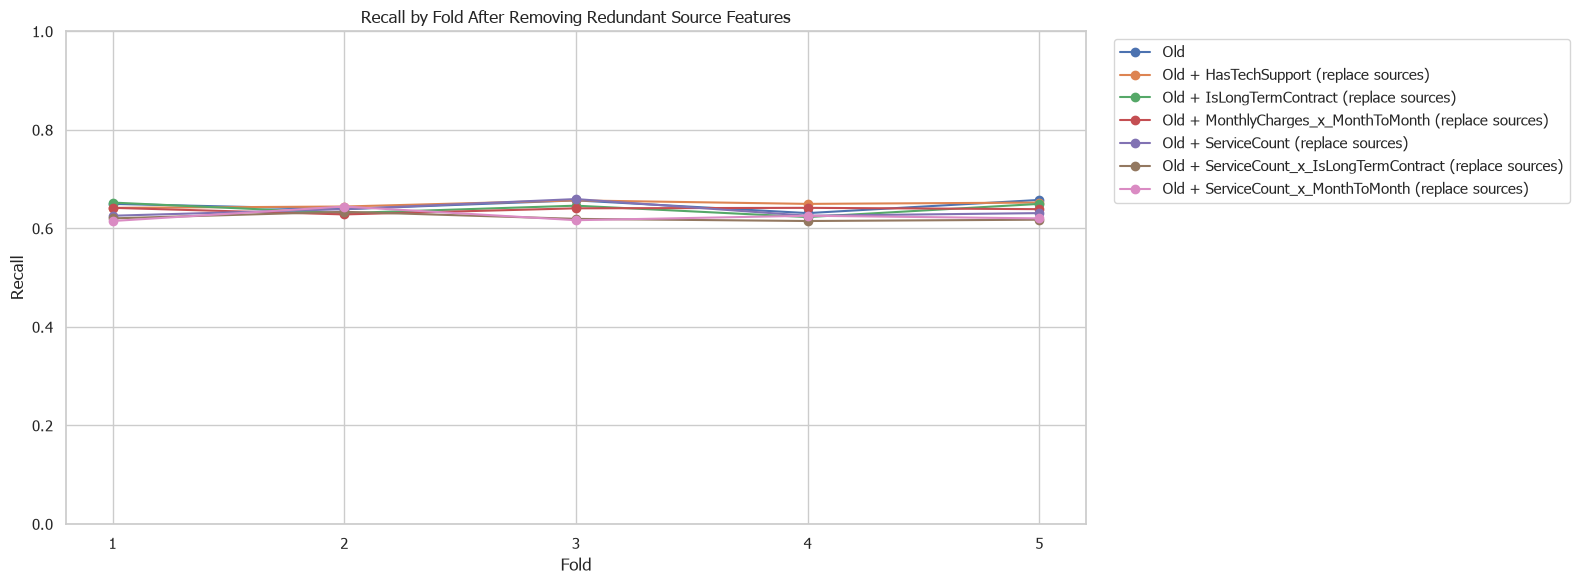

In [60]:
# Replacement feature sets: remove source columns when their information is summarized.
source_columns_by_feature = {
    'ServiceCount': service_columns,
    'IsLongTermContract': ['Contract'],
    'HasTechSupport': ['TechSupport'],
    'MonthlyCharges_x_MonthToMonth': ['Contract', 'MonthlyCharges'],
    'ServiceCount_x_MonthToMonth': service_columns + ['Contract'],
    'ServiceCount_x_IsLongTermContract': service_columns + ['Contract']
}

replacement_feature_sets = {'Old': classification_old.copy()}
for new_feature in new_feature_columns:
    replacement_features = classification_old.copy()
    columns_to_remove = [
        column for column in source_columns_by_feature[new_feature]
        if column in replacement_features.columns
    ]
    replacement_features = replacement_features.drop(columns=columns_to_remove)
    replacement_features[new_feature] = feature_df[new_feature]
    replacement_feature_sets[f'Old + {new_feature} (replace sources)'] = replacement_features

replacement_cv_results = []
replacement_fold_scores = []
for model_name, features in replacement_feature_sets.items():
    cv_model = make_classification_model(features)
    scores = cross_validate(
        cv_model,
        features,
        classification_target,
        cv=cv_splitter,
        scoring=cv_scoring,
        n_jobs=-1,
        return_train_score=False
    )
    replacement_cv_results.append({
        'Model': model_name,
        'Accuracy': scores['test_Accuracy'].mean(),
        'Precision': scores['test_Precision'].mean(),
        'Recall': scores['test_Recall'].mean(),
        'F1': scores['test_F1'].mean(),
        'ROC-AUC': scores['test_ROC-AUC'].mean()
    })
    replacement_fold_scores.append(pd.DataFrame({
        'Model': model_name,
        'Fold': np.arange(1, 6),
        'Recall': scores['test_Recall'],
        'F1': scores['test_F1'],
        'ROC-AUC': scores['test_ROC-AUC']
    }))

replacement_cv_results = pd.DataFrame(replacement_cv_results)
replacement_fold_scores = pd.concat(replacement_fold_scores, ignore_index=True)
print('5-fold CV with redundant source columns removed:')
display(replacement_cv_results.sort_values('Recall', ascending=False).round(4))

plt.figure(figsize=(16, 6))
replacement_cv_results.set_index('Model')[['Recall', 'F1', 'ROC-AUC']].plot(
    kind='bar',
    figsize=(16, 6),
    color=['#E45756', '#F58518', '#4C78A8']
)
plt.title('Replacement Features: Recall, F1 and ROC-AUC')
plt.ylabel('Mean score across 5 folds')
plt.ylim(0, 1)
plt.xticks(rotation=35, ha='right')
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

# Fold-level Recall reveals whether an improvement is consistent.
plt.figure(figsize=(16, 6))
for model_name, model_scores in replacement_fold_scores.groupby('Model'):
    plt.plot(
        model_scores['Fold'],
        model_scores['Recall'],
        marker='o',
        label=model_name
    )
plt.title('Recall by Fold After Removing Redundant Source Features')
plt.xlabel('Fold')
plt.ylabel('Recall')
plt.xticks(range(1, 6))
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Regression 5-Fold CV: Replacing Redundant Source Features

This experiment applies the same replacement idea to tenure regression. Lower RMSE/MAE and higher R2 are better.

Regression 5-fold CV after removing redundant source columns:


,Model,RMSE,MAE,R2
3,Old + HasTechSupport (replace sources),15.6351,12.0068,0.5940
0,Old,15.6357,12.0078,0.5940
1,Old + ServiceCount (replace sources),15.9833,12.2401,0.5757
4,Old + MonthlyCharges_x_MonthToMonth (replace s...,16.2127,12.5720,0.5634
2,Old + IsLongTermContract (replace sources),16.3092,12.6041,0.5583
6,Old + ServiceCount_x_IsLongTermContract (repla...,18.0645,13.9041,0.4580
5,Old + ServiceCount_x_MonthToMonth (replace sou...,18.1882,14.0408,0.4506


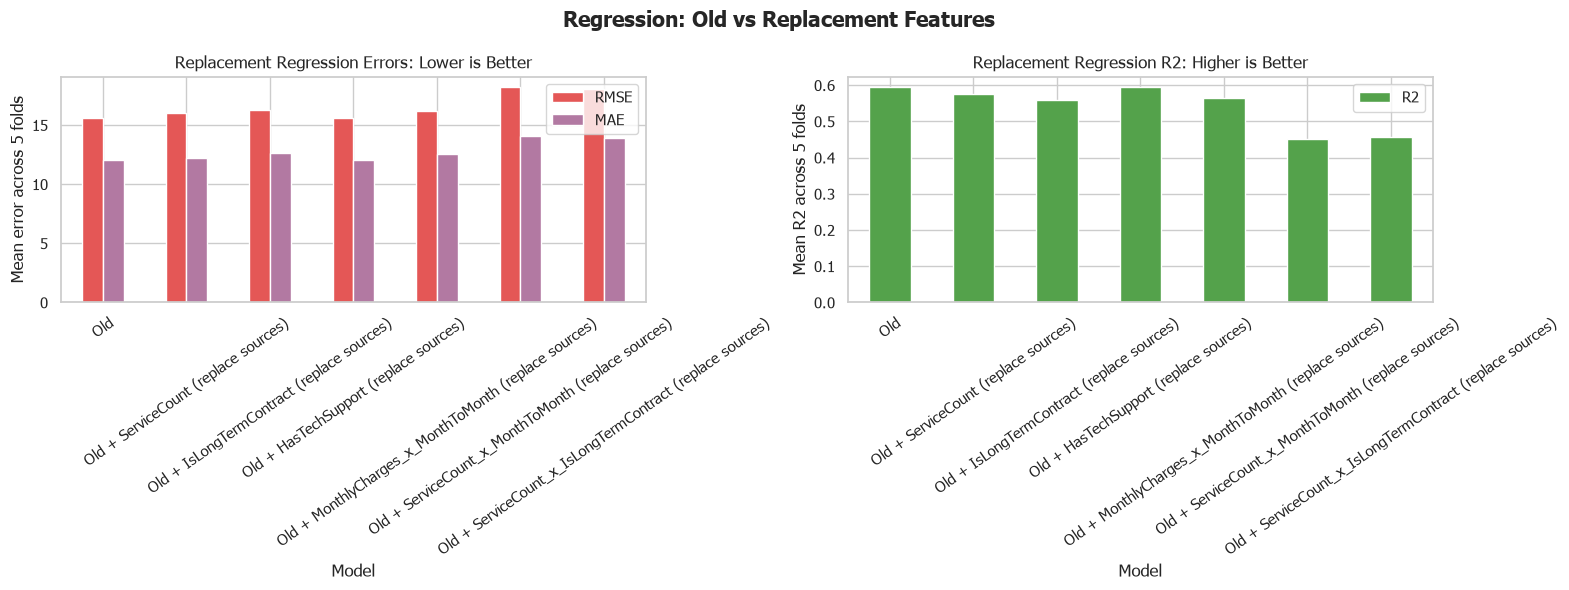

In [ ]:
regression_replacement_feature_sets = {'Old': regression_old.copy()}

for new_feature in new_feature_columns:
    replacement_features = regression_old.copy()
    columns_to_remove = [
        column for column in source_columns_by_feature[new_feature]
        if column in replacement_features.columns
    ]
    replacement_features = replacement_features.drop(columns=columns_to_remove)
    replacement_features[new_feature] = feature_df[new_feature]
    regression_replacement_feature_sets[
        f'Old + {new_feature} (replace sources)'
    ] = replacement_features

regression_replacement_results = []
for model_name, features in regression_replacement_feature_sets.items():
    regression_model_cv = make_regression_model(features)
    scores = cross_validate(
        regression_model_cv,
        features,
        regression_target,
        cv=regression_cv_splitter,
        scoring=regression_cv_scoring,
        n_jobs=-1
    )
    regression_replacement_results.append({
        'Model': model_name,
        'RMSE': -scores['test_RMSE'].mean(),
        'MAE': -scores['test_MAE'].mean(),
        'R2': scores['test_R2'].mean()
    })

regression_replacement_results = pd.DataFrame(regression_replacement_results)
print('Regression 5-fold CV after removing redundant source columns:')
display(regression_replacement_results.sort_values('RMSE').round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
regression_replacement_results.set_index('Model')[['RMSE', 'MAE']].plot(
    kind='bar',
    ax=axes[0],
    color=['#E45756', '#B279A2']
)
axes[0].set_title('Replacement Regression Errors: Lower is Better')
axes[0].set_ylabel('Mean error across 5 folds')
axes[0].tick_params(axis='x', rotation=35)

regression_replacement_results.set_index('Model')[['R2']].plot(
    kind='bar',
    ax=axes[1],
    color=['#54A24B']
)
axes[1].set_title('Replacement Regression R2: Higher is Better')
axes[1].set_ylabel('Mean R2 across 5 folds')
axes[1].tick_params(axis='x', rotation=35)

fig.suptitle('Regression: Old vs Replacement Features', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

## Scratch CatBoost-style vs Scratch LightGBM-style

These are educational implementations written in this notebook. They do not import CatBoost or LightGBM. Both use gradient boosting; the CatBoost-style model uses ordered target encoding, while the LightGBM-style model uses leaf-wise gradient tree growth. The comparison focuses on Recall for churn detection.

In [70]:
from sklearn.model_selection import StratifiedKFold


class ScratchBoostingClassifier:
    def __init__(
        self,
        style='catboost',
        n_estimators=80,
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=10,
        max_thresholds=25
    ):
        self.style = style
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_thresholds = max_thresholds

    def _encode(self, data, y=None, training=False):
        encoded = pd.DataFrame(index=data.index)
        for column in data.columns:
            values = data[column]
            if pd.api.types.is_numeric_dtype(values):
                encoded[column] = values.fillna(values.median()).astype(float)
                continue

            values = values.fillna('missing').astype(str)
            if training and self.style == 'catboost':
                prior = float(np.mean(y))
                sums = 0.0
                counts = 0.0
                ordered_values = []
                for value, target in zip(values, y):
                    ordered_values.append((sums + prior) / (counts + 1.0))
                    sums += target
                    counts += 1.0
                encoded[column] = ordered_values
                self.category_maps[column] = {}
                for value, target in zip(values, y):
                    total, count = self.category_maps[column].get(value, (0.0, 0.0))
                    self.category_maps[column][value] = (total + target, count + 1.0)
            else:
                if training:
                    self.category_maps[column] = {}
                    for value, target in zip(
                        values,
                        y if y is not None else np.zeros(len(values))
                    ):
                        total, count = self.category_maps[column].get(value, (0.0, 0.0))
                        self.category_maps[column][value] = (total + target, count + 1.0)
                prior = self.global_mean
                encoded[column] = [
                    (sum_count[0] + prior) / (sum_count[1] + 1.0)
                    if column in self.category_maps and value in self.category_maps[column]
                    else prior
                    for value in values
                    for sum_count in [
                        self.category_maps.get(column, {}).get(value, (0.0, 0.0))
                    ]
                ]
        return encoded.to_numpy(dtype=float)

    def _best_split(self, X, residual, indices):
        best = None
        base_error = np.sum((residual[indices] - np.mean(residual[indices])) ** 2)
        for feature_index in range(X.shape[1]):
            values = X[indices, feature_index]
            thresholds = np.unique(values)
            if len(thresholds) > self.max_thresholds:
                thresholds = np.quantile(
                    values,
                    np.linspace(0.05, 0.95, self.max_thresholds)
                )
            for threshold in thresholds:
                left_indices = indices[values <= threshold]
                right_indices = indices[values > threshold]
                if (
                    len(left_indices) < self.min_samples_leaf
                    or len(right_indices) < self.min_samples_leaf
                ):
                    continue
                left_value = np.mean(residual[left_indices])
                right_value = np.mean(residual[right_indices])
                error = np.sum((residual[left_indices] - left_value) ** 2)
                error += np.sum((residual[right_indices] - right_value) ** 2)
                gain = base_error - error
                if best is None or gain > best['gain']:
                    best = {
                        'feature': feature_index,
                        'threshold': threshold,
                        'left_indices': left_indices,
                        'right_indices': right_indices,
                        'gain': gain
                    }
        return best

    def _build_tree(self, X, residual, indices, depth):
        leaf_value = float(np.mean(residual[indices]))
        if depth >= self.max_depth or len(indices) < 2 * self.min_samples_leaf:
            return {'value': leaf_value}

        split = self._best_split(X, residual, indices)
        if split is None or split['gain'] <= 0:
            return {'value': leaf_value}

        return {
            'feature': split['feature'],
            'threshold': split['threshold'],
            'left': self._build_tree(
                X, residual, split['left_indices'], depth + 1
            ),
            'right': self._build_tree(
                X, residual, split['right_indices'], depth + 1
            )
        }

    def _predict_tree_row(self, tree, row):
        if 'value' in tree:
            return tree['value']
        if row[tree['feature']] <= tree['threshold']:
            return self._predict_tree_row(tree['left'], row)
        return self._predict_tree_row(tree['right'], row)

    def _predict_tree(self, tree, X):
        return np.array([
            self._predict_tree_row(tree, row)
            for row in X
        ])

    def fit(self, data, target):
        self.global_mean = float(np.mean(target))
        self.category_maps = {}
        X = self._encode(data, target, training=True)
        self.base_score = np.log(
            (self.global_mean + 1e-6) / (1 - self.global_mean + 1e-6)
        )
        raw_score = np.full(len(target), self.base_score)
        self.trees = []
        for _ in range(self.n_estimators):
            probability = 1 / (1 + np.exp(-raw_score))
            residual = target - probability
            tree = self._build_tree(
                X,
                residual,
                np.arange(len(target)),
                depth=0
            )
            update = self._predict_tree(tree, X)
            raw_score += self.learning_rate * update
            self.trees.append(tree)
        return self

    def predict_proba(self, data):
        X = self._encode(data, training=False)
        raw_score = np.full(len(data), self.base_score)
        for tree in self.trees:
            raw_score += self.learning_rate * self._predict_tree(tree, X)
        probability = 1 / (1 + np.exp(-raw_score))
        return np.column_stack([1 - probability, probability])

    def predict(self, data, threshold=0.5):
        return (self.predict_proba(data)[:, 1] >= threshold).astype(int)


print('max_depth now controls the maximum tree depth.')

max_depth now controls the maximum tree depth.


## Scratch Models: Threshold 0.25, 0.30, 0.35, 0.40

This single evaluation compares both scratch models at thresholds 0.25, 0.30, 0.35, 0.40 using the same 5-fold splits.

Scratch models using Old + HasTechSupport across thresholds 0.25 to 0.40:


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC
0,Scratch CatBoost-style,0.25,0.6542,0.4237,0.8357,0.5623,0.7905
1,Scratch CatBoost-style,0.30,0.7743,0.5789,0.5538,0.5660,0.7905
2,Scratch CatBoost-style,0.35,0.7837,0.6620,0.3804,0.4832,0.7905
3,Scratch CatBoost-style,0.40,0.7752,0.7209,0.2515,0.3729,0.7905
4,Scratch LightGBM-style,0.25,0.6539,0.4271,0.8855,0.5763,0.8197
5,Scratch LightGBM-style,0.30,0.7473,0.5169,0.7533,0.6131,0.8197
6,Scratch LightGBM-style,0.35,0.7750,0.5805,0.5538,0.5668,0.8197
7,Scratch LightGBM-style,0.40,0.7342,0.0000,0.0000,0.0000,0.8197


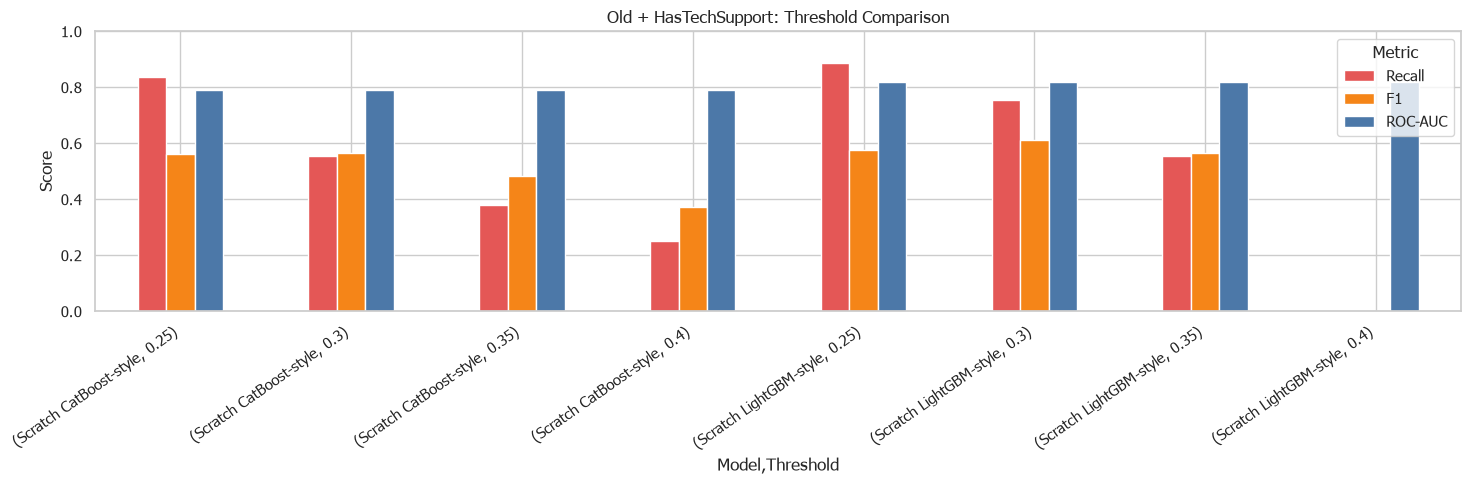

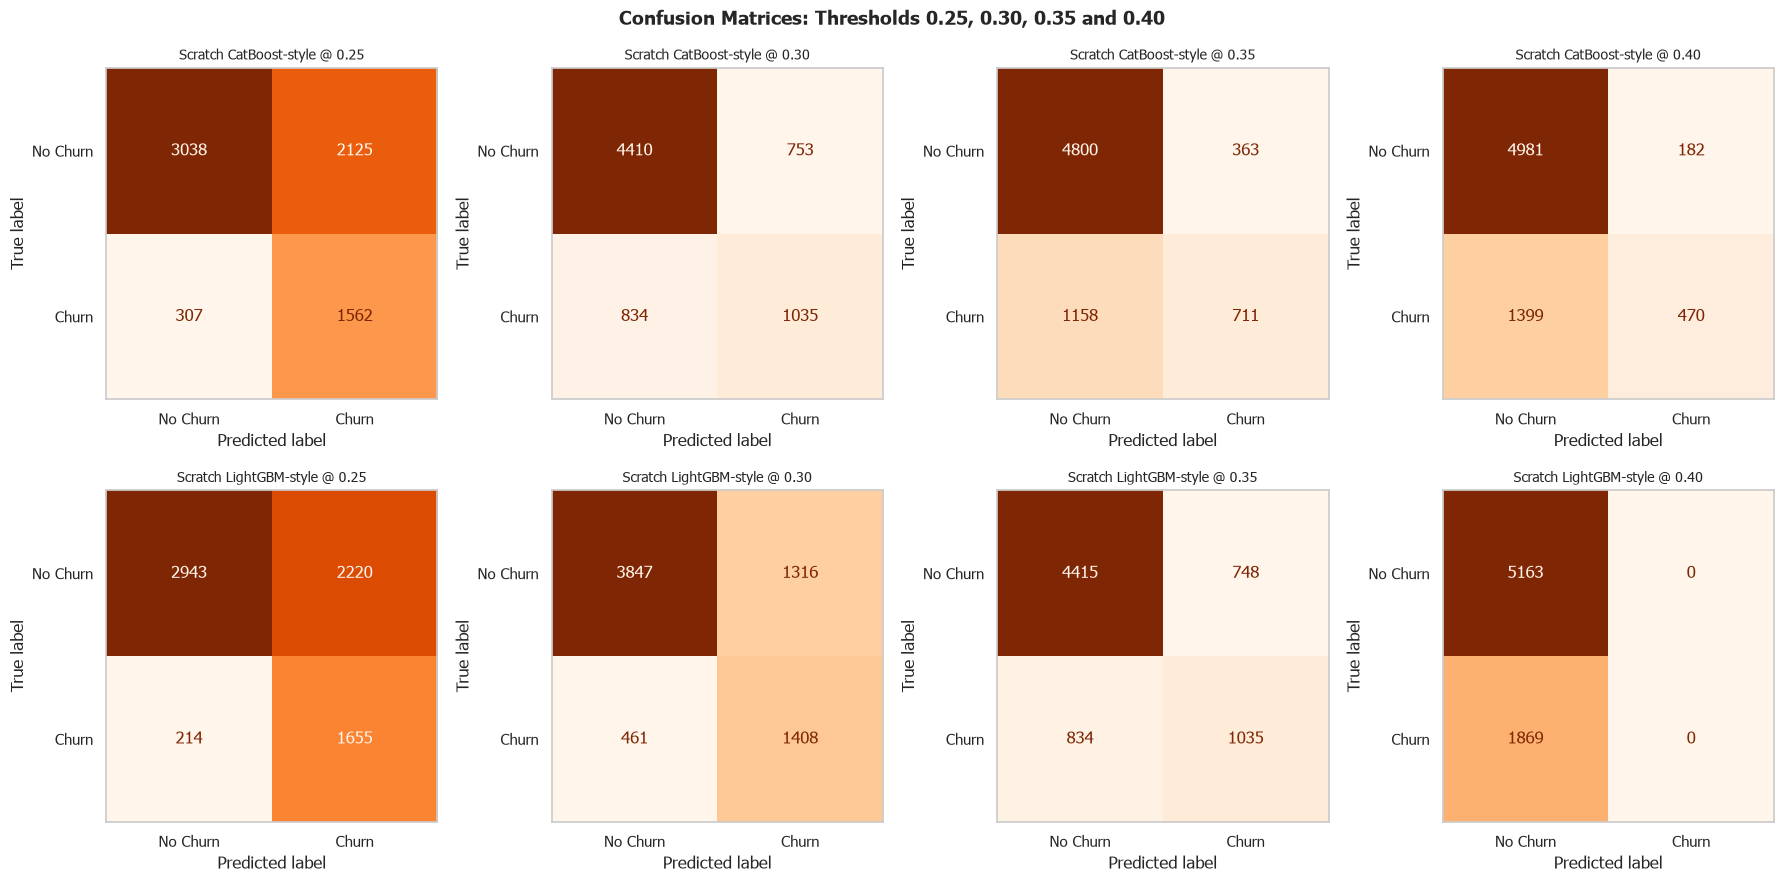

In [71]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Use Old + HasTechSupport, replacing the original TechSupport column.
scratch_features = replacement_feature_sets[
    'Old + HasTechSupport (replace sources)'
]

thresholds = [0.25, 0.30, 0.35, 0.40]
model_styles = [
    ('catboost', 'Scratch CatBoost-style'),
    ('lightgbm', 'Scratch LightGBM-style')
]
splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
threshold_results = []
threshold_predictions = {}

for style, model_name in model_styles:
    for threshold in thresholds:
        actual_all = []
        predictions_all = []
        probabilities_all = []

        for train_index, test_index in splitter.split(scratch_features, classification_target):
            model = ScratchBoostingClassifier(style=style)
            model.fit(
                scratch_features.iloc[train_index],
                classification_target.iloc[train_index].to_numpy()
            )
            probabilities = model.predict_proba(
                scratch_features.iloc[test_index]
            )[:, 1]
            predictions = (probabilities >= threshold).astype(int)
            actual = classification_target.iloc[test_index].to_numpy()

            actual_all.extend(actual)
            predictions_all.extend(predictions)
            probabilities_all.extend(probabilities)

        actual_all = np.array(actual_all)
        predictions_all = np.array(predictions_all)
        probabilities_all = np.array(probabilities_all)
        result_key = f'{model_name} @ {threshold:.2f}'
        threshold_predictions[result_key] = {
            'Actual': actual_all,
            'Predictions': predictions_all
        }
        threshold_results.append({
            'Model': model_name,
            'Threshold': threshold,
            'Accuracy': accuracy_score(actual_all, predictions_all),
            'Precision': precision_score(actual_all, predictions_all, zero_division=0),
            'Recall': recall_score(actual_all, predictions_all, zero_division=0),
            'F1': f1_score(actual_all, predictions_all, zero_division=0),
            'ROC-AUC': roc_auc_score(actual_all, probabilities_all)
        })

threshold_results = pd.DataFrame(threshold_results)
print('Scratch models using Old + HasTechSupport across thresholds 0.25 to 0.40:')
display(threshold_results.round(4))

threshold_results.set_index(['Model', 'Threshold'])[['Recall', 'F1', 'ROC-AUC']].plot(
    kind='bar',
    figsize=(15, 5),
    color=['#E45756', '#F58518', '#4C78A8']
)
plt.title('Old + HasTechSupport: Threshold Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=35, ha='right')
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for axis, (model_name, values) in zip(axes.ravel(), threshold_predictions.items()):
    matrix = confusion_matrix(values['Actual'], values['Predictions'])
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=['No Churn', 'Churn']
    ).plot(ax=axis, cmap='Oranges', colorbar=False)
    axis.grid(False)
    axis.set_title(model_name, fontsize=10)

fig.suptitle(
    'Confusion Matrices: Thresholds 0.25, 0.30, 0.35 and 0.40',
    fontsize=14,
    fontweight='bold'
)
plt.tight_layout()
plt.show()

## Regression: GAM, Ridge, Lasso and ElasticNet

The regression target is `tenure`. `TotalCharges` is deliberately excluded to prevent target leakage. The selected input is the best RMSE feature set from the previous comparison: Old features plus `ServiceCount x IsLongTermContract`.

Regression comparison using the selected feature set:


,Model,RMSE,MAE,R2
0,GAM (spline additive),14.5634,11.3748,0.6477
2,Lasso,14.5990,11.4263,0.6460
1,Ridge,14.5998,11.4204,0.6459
3,ElasticNet,14.6035,11.4623,0.6458


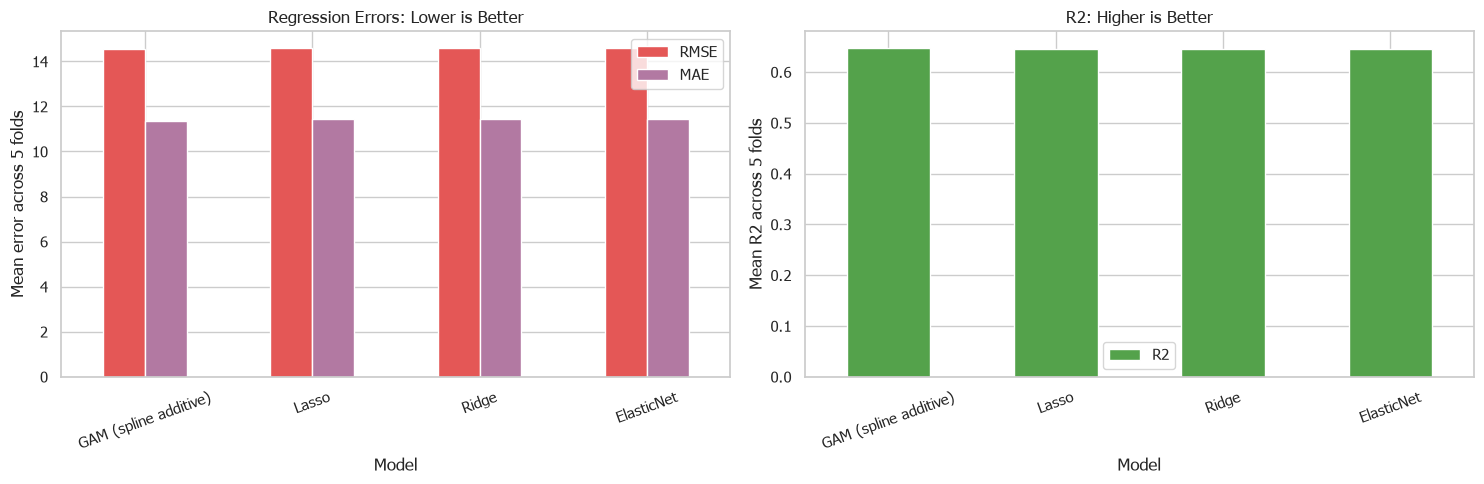

In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.metrics import make_scorer, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler

# Load and prepare data for tenure regression without TotalCharges.
gam_df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
gam_df['TotalCharges'] = pd.to_numeric(gam_df['TotalCharges'], errors='coerce')
gam_df = gam_df.dropna(subset=['TotalCharges']).copy()

service_columns = [
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies'
]
gam_df['ServiceCount'] = gam_df[service_columns].eq('Yes').sum(axis=1)
gam_df['IsLongTermContract'] = gam_df['Contract'].isin(
    ['One year', 'Two year']
).astype(int)
gam_df['ServiceCount_x_IsLongTermContract'] = (
    gam_df['ServiceCount'] * gam_df['IsLongTermContract']
)

# Best feature set by the previous RMSE table; TotalCharges is excluded explicitly.
gam_features = gam_df.drop(
    columns=[
        'tenure', 'TotalCharges', 'Churn', 'customerID', 'index',
        'ServiceCount', 'IsLongTermContract',
        'ServiceCount_x_MonthToMonth',
        'MonthlyCharges_x_MonthToMonth'
    ],
    errors='ignore'
)
gam_target = gam_df['tenure']

numeric_columns = gam_features.select_dtypes(include=['number']).columns.tolist()
categorical_columns = [
    column for column in gam_features.columns
    if column not in numeric_columns
]

# Standard linear models use scaled numeric values and one-hot categorical values.
linear_preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric_columns),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_columns)
])

# GAM-style model: spline basis for numeric columns plus additive categorical effects.
gam_preprocessor = ColumnTransformer([
    ('numeric_splines', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('splines', SplineTransformer(n_knots=5, degree=3, include_bias=False)),
        ('scaler', StandardScaler())
    ]), numeric_columns),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_columns)
])

models = {
    'GAM (spline additive)': Pipeline([
        ('preprocessor', gam_preprocessor),
        ('model', Ridge(alpha=1.0))
    ]),
    'Ridge': Pipeline([
        ('preprocessor', linear_preprocessor),
        ('model', Ridge(alpha=1.0))
    ]),
    'Lasso': Pipeline([
        ('preprocessor', linear_preprocessor),
        ('model', Lasso(alpha=0.01, max_iter=20000))
    ]),
    'ElasticNet': Pipeline([
        ('preprocessor', linear_preprocessor),
        ('model', ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=20000))
    ])
}

regression_scoring = {
    'RMSE': make_scorer(
        lambda actual, predicted: np.sqrt(mean_squared_error(actual, predicted)),
        greater_is_better=False
    ),
    'MAE': make_scorer(mean_absolute_error, greater_is_better=False),
    'R2': make_scorer(r2_score)
}

regression_cv = KFold(n_splits=5, shuffle=True, random_state=42)
model_results = []
for model_name, model in models.items():
    scores = cross_validate(
        model,
        gam_features,
        gam_target,
        cv=regression_cv,
        scoring=regression_scoring,
        n_jobs=-1
    )
    model_results.append({
        'Model': model_name,
        'RMSE': -scores['test_RMSE'].mean(),
        'MAE': -scores['test_MAE'].mean(),
        'R2': scores['test_R2'].mean()
    })

regression_model_results = pd.DataFrame(model_results).sort_values('RMSE')
print('Regression comparison using the selected feature set:')
display(regression_model_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
regression_model_results.set_index('Model')[['RMSE', 'MAE']].plot(
    kind='bar', ax=axes[0], color=['#E45756', '#B279A2']
)
axes[0].set_title('Regression Errors: Lower is Better')
axes[0].set_ylabel('Mean error across 5 folds')
axes[0].tick_params(axis='x', rotation=20)

regression_model_results.set_index('Model')[['R2']].plot(
    kind='bar', ax=axes[1], color=['#54A24B']
)
axes[1].set_title('R2: Higher is Better')
axes[1].set_ylabel('Mean R2 across 5 folds')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

Best GAM hyperparameters from 5-fold CV:
n_knots = 8
alpha = 10.0
Best GAM result:


,n_knots,alpha,RMSE,MAE,R2
19,8,10.0,14.5624,11.3783,0.6478
7,5,10.0,14.5633,11.3895,0.6477
6,5,1.0,14.5634,11.3748,0.6477
18,8,1.0,14.5638,11.3689,0.6477
2,4,1.0,14.5647,11.3796,0.6476


Best GAM hyperparameters from 5-fold CV:
n_knots = 8
alpha = 10.0
Best GAM result:


,n_knots,alpha,RMSE,MAE,R2
19,8,10.0,14.5624,11.3783,0.6478
7,5,10.0,14.5633,11.3895,0.6477
6,5,1.0,14.5634,11.3748,0.6477
18,8,1.0,14.5638,11.3689,0.6477
2,4,1.0,14.5647,11.3796,0.6476


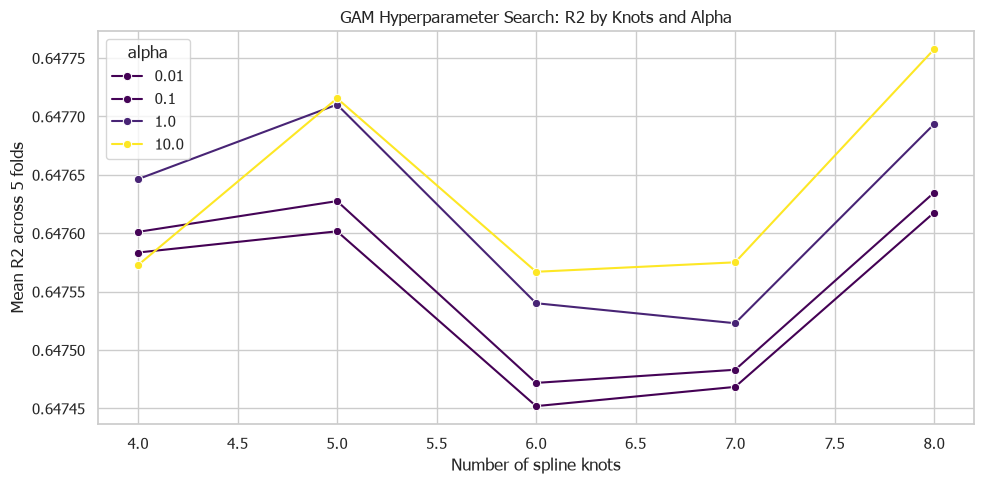

In [77]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import make_scorer, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler

# Tuned GAM configuration: more flexible splines with adjustable regularization.
GAM_N_KNOTS = 7
GAM_ALPHA = 0.1

numeric_columns = gam_features.select_dtypes(include=['number']).columns.tolist()
categorical_columns = [
    column for column in gam_features.columns
    if column not in numeric_columns
]

regression_scoring = {
    'RMSE': make_scorer(
        lambda actual, predicted: np.sqrt(mean_squared_error(actual, predicted)),
        greater_is_better=False
    ),
    'MAE': make_scorer(mean_absolute_error, greater_is_better=False),
    'R2': make_scorer(r2_score)
}
regression_cv = KFold(n_splits=5, shuffle=True, random_state=42)

tuned_gam_preprocessor = ColumnTransformer([
    ('numeric_splines', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('splines', SplineTransformer(
            n_knots=GAM_N_KNOTS,
            degree=3,
            include_bias=False
        )),
        ('scaler', StandardScaler())
    ]), numeric_columns),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_columns)
])

tuned_gam_model = Pipeline([
    ('preprocessor', tuned_gam_preprocessor),
    ('model', Ridge(alpha=GAM_ALPHA))
])

tuned_gam_scores = cross_validate(
    tuned_gam_model,
    gam_features,
    gam_target,
    cv=regression_cv,
    scoring=regression_scoring,
    n_jobs=-1
)

tuned_gam_result = pd.DataFrame([{
    'Model': f'GAM tuned (knots={GAM_N_KNOTS}, alpha={GAM_ALPHA})',
    'RMSE': -tuned_gam_scores['test_RMSE'].mean(),
    'MAE': -tuned_gam_scores['test_MAE'].mean(),
    'R2': tuned_gam_scores['test_R2'].mean()
}])

print('Tuned GAM hyperparameters:')
print(f'n_knots = {GAM_N_KNOTS}, alpha = {GAM_ALPHA}')
display(tuned_gam_result.round(4))

## From-Scratch Regression: GAM, Ridge, Lasso and ElasticNet

These regression models are implemented with NumPy and gradient descent. No sklearn regression estimator is used, and `TotalCharges` is excluded.

In [69]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Central hyperparameters: change these values to tune the from-scratch models.
SCRATCH_REGRESSION_PARAMS = {
    'learning_rate': 0.005,
    'iterations': 40000,
    'alpha': 0.01,
    'l1_ratio': 0.5
}

# Selected regression inputs: exclude tenure, TotalCharges and identifiers.
scratch_reg_df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
scratch_reg_df['TotalCharges'] = pd.to_numeric(
    scratch_reg_df['TotalCharges'], errors='coerce'
)
scratch_reg_df = scratch_reg_df.dropna(subset=['TotalCharges']).copy()
service_columns = [
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies'
]
scratch_reg_df['ServiceCount'] = scratch_reg_df[service_columns].eq('Yes').sum(axis=1)
scratch_reg_df['IsLongTermContract'] = scratch_reg_df['Contract'].isin(
    ['One year', 'Two year']
).astype(int)
scratch_reg_df['ServiceCount_x_IsLongTermContract'] = (
    scratch_reg_df['ServiceCount'] * scratch_reg_df['IsLongTermContract']
)
scratch_reg_features = scratch_reg_df.drop(
    columns=[
        'tenure', 'TotalCharges', 'Churn', 'customerID', 'index',
        'ServiceCount', 'IsLongTermContract',
        'ServiceCount_x_MonthToMonth',
        'MonthlyCharges_x_MonthToMonth'
    ],
    errors='ignore'
)
scratch_reg_target = scratch_reg_df['tenure'].to_numpy(dtype=float)


def prepare_matrix(train_data, test_data, gam=False):
    numeric = train_data.select_dtypes(include=['number']).columns.tolist()
    categorical = [column for column in train_data.columns if column not in numeric]
    train_num = train_data[numeric].copy()
    test_num = test_data[numeric].copy()
    for column in numeric:
        median = train_num[column].median()
        train_num[column] = train_num[column].fillna(median)
        test_num[column] = test_num[column].fillna(median)
    means = train_num.mean()
    scales = train_num.std().replace(0, 1).fillna(1)
    train_num = ((train_num - means) / scales).to_numpy(dtype=float)
    test_num = ((test_num - means) / scales).to_numpy(dtype=float)

    if gam:
        train_parts = []
        test_parts = []
        for index in range(train_num.shape[1]):
            train_value = train_num[:, index]
            test_value = test_num[:, index]
            knots = np.quantile(train_value, [0.2, 0.4, 0.6, 0.8])
            train_parts.extend([train_value, train_value ** 2, train_value ** 3])
            test_parts.extend([test_value, test_value ** 2, test_value ** 3])
            for knot in knots:
                train_parts.append(np.maximum(train_value - knot, 0) ** 3)
                test_parts.append(np.maximum(test_value - knot, 0) ** 3)
        train_num = np.column_stack(train_parts)
        test_num = np.column_stack(test_parts)

    if categorical:
        train_cat = train_data[categorical].fillna('missing').astype(str)
        test_cat = test_data[categorical].fillna('missing').astype(str)
        combined = pd.get_dummies(pd.concat([train_cat, test_cat]), dtype=float)
        train_cat = combined.iloc[:len(train_data)].to_numpy(dtype=float)
        test_cat = combined.iloc[len(train_data):].to_numpy(dtype=float)
        train_matrix = np.column_stack([train_num, train_cat])
        test_matrix = np.column_stack([test_num, test_cat])
    else:
        train_matrix = train_num
        test_matrix = test_num

    # Normalize every generated column to keep gradient descent stable.
    column_scale = np.std(train_matrix, axis=0)
    column_scale[column_scale < 1e-8] = 1.0
    train_matrix = train_matrix / column_scale
    test_matrix = test_matrix / column_scale
    return (
        np.column_stack([np.ones(len(train_matrix)), train_matrix]),
        np.column_stack([np.ones(len(test_matrix)), test_matrix])
    )


def soft_threshold(values, amount):
    return np.sign(values) * np.maximum(np.abs(values) - amount, 0)


def fit_from_scratch(
    X,
    y,
    penalty='ridge',
    learning_rate=SCRATCH_REGRESSION_PARAMS['learning_rate'],
    iterations=SCRATCH_REGRESSION_PARAMS['iterations'],
    alpha=SCRATCH_REGRESSION_PARAMS['alpha'],
    l1_ratio=SCRATCH_REGRESSION_PARAMS['l1_ratio']
):
    coefficients = np.zeros(X.shape[1])
    for _ in range(iterations):
        predictions = X @ coefficients
        gradient = (2 / len(y)) * (X.T @ (predictions - y))
        gradient[0] = 0
        gradient = np.clip(gradient, -10, 10)
        if penalty == 'ridge':
            gradient[1:] += 2 * alpha * coefficients[1:]
            coefficients -= learning_rate * gradient
        elif penalty == 'lasso':
            coefficients -= learning_rate * gradient
            coefficients[1:] = soft_threshold(
                coefficients[1:], learning_rate * alpha
            )
        elif penalty == 'elasticnet':
            coefficients -= learning_rate * (
                gradient + alpha * (1 - l1_ratio) * coefficients
            )
            coefficients[1:] = soft_threshold(
                coefficients[1:], learning_rate * alpha * l1_ratio
            )
    return coefficients


models_from_scratch = {
    'GAM from scratch': {'gam': True, 'penalty': 'ridge'},
    'Ridge from scratch': {'gam': False, 'penalty': 'ridge'},
    'Lasso from scratch': {'gam': False, 'penalty': 'lasso'},
    'ElasticNet from scratch': {'gam': False, 'penalty': 'elasticnet'}
}

folds = KFold(n_splits=5, shuffle=True, random_state=42)
from_scratch_results = []
for model_name, settings in models_from_scratch.items():
    fold_metrics = []
    for train_index, test_index in folds.split(scratch_reg_features):
        X_train_scratch, X_test_scratch = prepare_matrix(
            scratch_reg_features.iloc[train_index],
            scratch_reg_features.iloc[test_index],
            gam=settings['gam']
        )
        target_mean = scratch_reg_target[train_index].mean()
        target_scale = scratch_reg_target[train_index].std()
        target_scale = target_scale if target_scale > 1e-8 else 1.0
        coefficients = fit_from_scratch(
            X_train_scratch,
            (scratch_reg_target[train_index] - target_mean) / target_scale,
            penalty=settings['penalty']
        )
        predictions = (X_test_scratch @ coefficients) * target_scale + target_mean
        actual = scratch_reg_target[test_index]
        fold_metrics.append({
            'RMSE': np.sqrt(mean_squared_error(actual, predictions)),
            'MAE': mean_absolute_error(actual, predictions),
            'R2': r2_score(actual, predictions)
        })
    mean_metrics = pd.DataFrame(fold_metrics).mean()
    from_scratch_results.append({
        'Model': model_name,
        'RMSE': mean_metrics['RMSE'],
        'MAE': mean_metrics['MAE'],
        'R2': mean_metrics['R2']
    })

from_scratch_results = pd.DataFrame(from_scratch_results).sort_values('RMSE')
print('From-scratch regression hyperparameters:')
display(pd.Series(SCRATCH_REGRESSION_PARAMS, name='Value'))
print('From-scratch regression comparison without TotalCharges:')
display(from_scratch_results.round(4))

From-scratch regression hyperparameters:


learning_rate        0.005
iterations       40000.000
alpha                0.010
l1_ratio             0.500
Name: Value, dtype: float64

From-scratch regression comparison without TotalCharges:


,Model,RMSE,MAE,R2
0,GAM from scratch,14.5675,11.3897,0.6475
1,Ridge from scratch,14.5993,11.4368,0.6460
3,ElasticNet from scratch,14.6052,11.4542,0.6457
2,Lasso from scratch,14.6207,11.4872,0.6449
